# Práctica 2 — Introducción al aprendizaje supervisado

**Machine Learning · Máster Universitario en Inteligencia Artificial · curso 2026/2027**

Grupo: *4* · Integrantes: *Carlos Chapman Peña*, *Miguel Ángel Gordillo Masero*, *María Xiaolan Ríos Díaz*, *Pablo Sola Díaz*

---

Cuaderno **de partida**. La primera celda de código fija vuestro grupo y vuestra semilla y carga
los datos; la última escribe los dos ficheros que subís a Kaggle. **Entre medias, el cuaderno es
vuestro**: los títulos de los ejercicios solo marcan el orden. La interpretación va en celdas
Markdown, no en comentarios de Python.

## 0. Entorno, semilla y datos

Declarad `GRUPO` y `SEMILLA` antes de nada. **Toda la aleatoriedad del cuaderno sale de
`SEMILLA`**: las particiones de la validación, los desempates y cualquier `random_state`.

In [1]:
# --- Práctica 2: grupo, semilla, entorno y datos --------------------------------
GRUPO = 4        # vuestro número de grupo (entero)
SEMILLA = 67      # vuestra semilla (entero): toda la aleatoriedad sale de aquí

import os, sys, platform
import numpy as np, pandas as pd, matplotlib, sklearn, scipy
import matplotlib.pyplot as plt

assert isinstance(GRUPO, int) and isinstance(SEMILLA, int), "Declarad GRUPO y SEMILLA (enteros) antes de seguir."

DATOS = os.path.join("..", "Datos")                  # relativa a este cuaderno
sys.path.insert(0, os.path.join("..", "Codigo"))     # código proporcionado por el curso
from oner import OneRClassifier, OneRRegressor
from comprobar_estimador import comprobar_estimador

ciber_train = pd.read_csv(os.path.join(DATOS, "ciber_train.csv"))
ciber_test = pd.read_csv(os.path.join(DATOS, "ciber_test.csv"))
latencia_train = pd.read_csv(os.path.join(DATOS, "latencia_train.csv"))
latencia_test = pd.read_csv(os.path.join(DATOS, "latencia_test.csv"))

X_CIBER = [c for c in ciber_test.columns if c != "id"]          # características de ciber
X_LATENCIA = [c for c in latencia_test.columns if c != "id"]    # características de latencia

print("python      ", platform.python_version())
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("GRUPO       ", GRUPO, "· SEMILLA", SEMILLA)
print("ciber       ", ciber_train.shape, ciber_test.shape)
print("latencia    ", latencia_train.shape, latencia_test.shape)

python       3.13.5
numpy        2.1.3
pandas       2.2.3
scikit-learn 1.6.1
GRUPO        4 · SEMILLA 67
ciber        (5000, 13) (5000, 12)
latencia     (5000, 11) (3000, 10)


## Ejercicio 1. Cómo vais a medir

*(TODO)*

### 1(a) Datos de ciber_train

In [2]:
ciber_train.info()
#Contar valores nulos
nulos_ciber = ciber_train.isnull().sum()
print(nulos_ciber)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            5000 non-null   object 
 1   proto         5000 non-null   object 
 2   service       5000 non-null   object 
 3   conn_state    5000 non-null   object 
 4   duration      5000 non-null   float64
 5   src_bytes     5000 non-null   int64  
 6   dst_bytes     5000 non-null   int64  
 7   missed_bytes  5000 non-null   int64  
 8   src_pkts      5000 non-null   int64  
 9   src_ip_bytes  5000 non-null   int64  
 10  dst_pkts      5000 non-null   int64  
 11  dst_ip_bytes  5000 non-null   int64  
 12  attack_type   5000 non-null   object 
dtypes: float64(1), int64(7), object(5)
memory usage: 507.9+ KB
id              0
proto           0
service         0
conn_state      0
duration        0
src_bytes       0
dst_bytes       0
missed_bytes    0
src_pkts        0
src_ip_bytes    0
dst_

### 1(a) Datos de latencia_train

In [3]:
# Información general
latencia_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             5000 non-null   object 
 1   block_size     5000 non-null   int64  
 2   n_jobs         5000 non-null   int64  
 3   iodepth        5000 non-null   int64  
 4   read_fraction  5000 non-null   int64  
 5   load_type      5000 non-null   object 
 6   io_type        5000 non-null   object 
 7   raid           5000 non-null   object 
 8   n_disks        5000 non-null   int64  
 9   device_type    5000 non-null   object 
 10  latency_ns     5000 non-null   float64
dtypes: float64(1), int64(5), object(5)
memory usage: 429.8+ KB


Con .info() comprobamos que no hay valores nulos en ninguna de las características del conjunto de datos y podemos ver el tipo de dato de cada una.

In [4]:
display(latencia_train.describe())

nominales = ['load_type', 'io_type', 'raid', 'device_type']
for col in nominales:
    print(latencia_train[col].value_counts())
    print("\n")

,block_size,n_jobs,iodepth,read_fraction,n_disks,latency_ns
count,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,208.576000,16.88100,16.934000,40.684000,17.994000,2.407129e+07
std,301.354501,15.54494,10.060412,36.357097,6.719598,9.319971e+07
min,4.000000,1.00000,1.000000,0.000000,3.000000,1.143315e+05
25%,16.000000,6.00000,8.000000,0.000000,12.000000,6.099692e+05
50%,64.000000,12.00000,15.000000,35.000000,20.000000,1.240523e+06
75%,256.000000,20.00000,27.000000,75.000000,24.000000,8.127825e+06
max,1024.000000,64.00000,32.000000,100.000000,24.000000,1.262194e+09


load_type
random        3270
sequential    1730
Name: count, dtype: int64


io_type
write    2980
read     2020
Name: count, dtype: int64


raid
4+1    2180
2+2     600
4+2     565
8+2     560
1+1     560
2+1     535
Name: count, dtype: int64


device_type
nvme    4210
hdd      790
Name: count, dtype: int64




Con .describe() mostramos un resumen estadístico de las características, que incluye la media, la desviación típica, los cuartiles y los valores mínimos y máximos. A partir de estos últimos, podemos observar que las características tienen escalas bastante diferentes. Por ejemplo, `block_size` toma valores entre 4 y 1024, mientras que los valores de `latency_ns` son mucho más elevados, llegando hasta 1.262.194.000. Otras variables, como `n_jobs` e `iodepth`, tienen rangos más reducidos. Estas diferencias de escala deben tenerse en cuenta durante el preprocesamiento, porque puede ser necesario aplicar técnicas de normalización o estandarización antes de entrenar el modelo.

Por otro lado, las variables categóricas muestran distribuciones desiguales: en `load_type` predomina random (3.270) frente a sequential (1.730); en `io_type` también hay más registros de write (2.980) que de read (2.020); en `raid` destaca 4+1 como la configuración más frecuente (2.180), mientras que las demás tienen frecuencias similares, con valores entre 535 y 600 registros; y en `device_type` domina claramente nvme (4.210) sobre hdd (790).

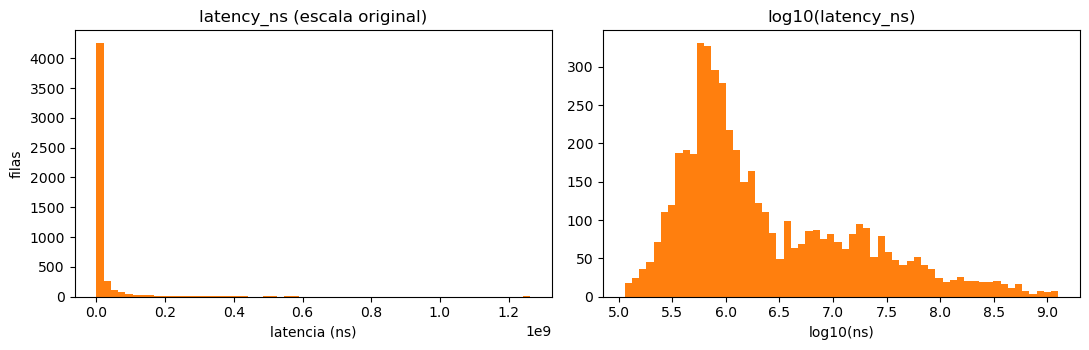

In [5]:
# Distribución de la variable objetivo (latencia_ns) en train
y = latencia_train["latency_ns"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(y, bins=60, color="C1"); ax[0].set_title("latency_ns (escala original)")
ax[0].set_xlabel("latencia (ns)"); ax[0].set_ylabel("filas")
ax[1].hist(np.log10(y), bins=60, color="C1"); ax[1].set_title("log10(latency_ns)")
ax[1].set_xlabel("log10(ns)")
plt.tight_layout(); plt.show()

En las gráficas podemos observar la distribución de la variable objetivo (`latency_ns`) tanto en su escala original como después de aplicar la transformación logarítmica `log10`.

En la escala original, la distribución es muy asimétrica hacia la derecha, ya que la mayoría de las observaciones tienen valores bajos, mientras que existen algunos valores de latencia muy altos que alargan la distribución.

Al aplicar la transformación logarítmica, reducimos esta asimetría y visualizamos mejor la distribución de los datos. De esta forma, podemos observar con más claridad las diferencias entre las latencias y conocer mejor el comportamiento de la variable antes de utilizarla en el modelo.

In [6]:
# Cuánto varían las cinco ejecuciones de una misma configuración

# Se definen las columnas que representan la "configuración" (todas menos 'id' y 'latency_ns')
configuracion = [c for c in latencia_train.columns if c not in ['id', 'latency_ns']]

grupos_lat = latencia_train.groupby(configuracion)["latency_ns"]
ratio_max_min = grupos_lat.max() / grupos_lat.min()
std_log10 = grupos_lat.apply(lambda s: np.log10(s).std(ddof=1))

resumen_var = pd.DataFrame({
    "ratio_max_min": ratio_max_min,
    "std_log10_ns": std_log10,
})
print("Resumen de variabilidad entre las 5 ejecuciones (1.000 configuraciones):")
display(
    resumen_var.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).T[[
        "count",
        "mean",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "90%",
        "max",
    ]]
)

# Ejemplo de una configuración y sus 5 latencias distintas
ejecuciones = grupos_lat.size()
ejemplo = ejecuciones[ejecuciones == 5].index[0]
ejemplo = (latencia_train[configuracion] == ejemplo).all(axis=1)
ejemplo = latencia_train[ejemplo][['block_size', 'n_jobs', 'iodepth', 'read_fraction', 'load_type', 'io_type', 'raid', 'n_disks', 'device_type', 'latency_ns']]
print("\nEjemplo de las 5 ejecuciones para una misma configuración:")
display(ejemplo)
latencias = ejemplo['latency_ns']

Resumen de variabilidad entre las 5 ejecuciones (1.000 configuraciones):


,count,mean,std,min,25%,50%,75%,90%,max
ratio_max_min,1000.0,1.287067,1.139653,1.000245,1.021795,1.068416,1.223296,1.572391,26.24800
std_log10_ns,1000.0,0.030703,0.053001,0.000044,0.003833,0.011891,0.035911,0.080515,0.62397



Ejemplo de las 5 ejecuciones para una misma configuración:


,block_size,n_jobs,iodepth,read_fraction,load_type,io_type,raid,n_disks,device_type,latency_ns
408,4,2,11,23,random,read,4+1,24,nvme,121127.5
543,4,2,11,23,random,read,4+1,24,nvme,117519.0
3819,4,2,11,23,random,read,4+1,24,nvme,116699.0
4349,4,2,11,23,random,read,4+1,24,nvme,119568.5
4960,4,2,11,23,random,read,4+1,24,nvme,118525.0


La primera tabla muestra cuánto varía la latencia (`latency_ns`) entre las 5 repeticiones de cada una de las 1.000 configuraciones únicas. Para ello, se utilizan dos métricas:
* **`ratio_max_min`**: indica cuántas veces mayor es la latencia máxima respecto a la mínima de una misma configuración. Un valor cercano a 1 significa que las ejecuciones han tenido resultados muy similares, mientras que valores más altos indican una mayor diferencia entre ellas.
* **`std_log10_ns`**: mide la desviación típica de `log10(latency_ns)` dentro de cada configuración. Permite analizar la variabilidad teniendo en cuenta que las diferencias de latencia pueden ser multiplicativas y no siempre siguen una distribución simétrica.

### Resumen de variabilidad

En la mayoría de las configuraciones se observa una variabilidad bastante baja entre las cinco repeticiones. La mediana (`50%`) de `ratio_max_min` es 1.068, lo que significa que, en un caso típico, la ejecución más lenta tarda aproximadamente un 6,8 % más que la más rápida. Además, en el `75 %` de las configuraciones el ratio no supera 1.223. La mediana de `std_log10_ns` también es baja (0.0119), lo que confirma que, por lo general, las distintas ejecuciones ofrecen resultados bastante similares.

Sin embargo, hay algunas configuraciones que presentan diferencias mucho más importantes entre repeticiones. Esto se refleja en que la media de `ratio_max_min` (1.287) es superior a su mediana (1.068), lo que indica que existen algunos valores extremos que elevan el promedio. Aunque la mayoría de los casos son bastante estables, el percentil 90 alcanza 1.572 y el valor máximo llega a 26.248. Esto significa que, en alguna configuración concreta, la ejecución más lenta ha tardado más de 26 veces que la más rápida.

Estos resultados muestran que una misma configuración no siempre produce exactamente la misma latencia, ya que existen variaciones entre sus distintas ejecuciones, probablemente debido a la existencia de ruido.

### Ejemplo

La segunda tabla muestra un ejemplo concreto de la variabilidad de la latencia en las cinco ejecuciones de una configuración. En este caso, se puede ver que no varía demasiado.

**¿Qué hace difícil este problema?**

La predicción de la latencia es difícil debido a diferentes cosas:

- **Asimetría de su distribución:** La variable objetivo tiene un rango de valores muy amplio (desde aproximadamente $10^5$ hasta $10^9$ ns) y una distribución muy sesgada. Esto es importante porque el $MAE_{\log}$ calcula el error absoluto medio sobre el logaritmo decimal de la latencia:
   $$MAE_{\log} = \frac{1}{n} \sum_{i=1}^{n} \vert{}\log_{10} y_i - \log_{10} \hat{y}_i\vert{}$$
   A diferencia del $MAE$, que mide las diferencias absolutas en las unidades originales y hace que los errores en valores más altos tengan mayor peso, el $MAE_{\log}$ tiene en cuenta los errores relativos. De esta forma, evita que las latencias más elevadas condicionen tanto el resultado de la evaluación. Esto significa que un error multiplicativo del mismo tamaño (por ejemplo, desviarse por un factor de 1.26) recibe la misma penalización, independientemente de si se produce en latencias de microsegundos o de milisegundos.

- **La variabilidad entre ejecuciones de una misma configuración:** Como hemos visto en la tabla anterior, los resultados de las cinco repeticiones de una misma configuración varían un poco debido al ruido, lo que planteará la decisión de si entrenar el modelo con todas las filas o calcular un valor medio que represente cada configuración en el Ejercicio 3.

- **Que puedan existir relaciones no lineales e interacciones entre las características:** El rendimiento del almacenamiento depende de varios factores que se influyen entre sí, como el tamaño de bloque, la profundidad de cola, el número de hilos y el tipo de RAID. Por ello, es necesario utilizar modelos que puedan detectar cómo afectan sus distintas combinaciones al rendimiento.

- **Hay variables numéricas y categóricas:** Como el conjunto de datos combina ambos tipos de variables, es necesario realizar un preprocesamiento adecuado antes de entrenar el modelo. Para ello, se deberán transformar las variables categóricas mediante técnicas de codificación y escalar las numéricas para evitar que unas tengan más peso que otras. Esto es muy importante en KNN porque utiliza distancias para determinar qué configuraciones son más similares entre sí.

### 1(b) Protocolos de validación de latencia_train

In [7]:
from sklearn.model_selection import GroupKFold, KFold

# Identificador de grupo: cada configuración única de hardware/carga (1.000 grupos)
cols_config = [c for c in X_LATENCIA]
grupos_latencia = latencia_train.groupby(cols_config, dropna=False).ngroup()

# Métrica oficial de la competición: error absoluto medio en log10(latency_ns)
def mae_log(y_true, y_pred):
  y_true = np.asarray(y_true, dtype=float)
  y_pred = np.asarray(y_pred, dtype=float)
  assert np.all(y_true > 0) and np.all(y_pred > 0), (
      "y_true y y_pred deben ser positivos"
  )
  return float(np.mean(np.abs(np.log10(y_true) - np.log10(y_pred))))


# Esquemas de validación candidatos (K = 5 particiones)
cv_agrupada = GroupKFold(n_splits=5)
cv_aleatoria = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# Comprobación de solapamiento de configuraciones entre train y validación
solap_agrupada = []
solap_aleatoria = []

for tr_idx, va_idx in cv_agrupada.split(
    latencia_train, latencia_train["latency_ns"], groups=grupos_latencia
):
  solap_agrupada.append(
      len(
          set(grupos_latencia.iloc[tr_idx]) & set(grupos_latencia.iloc[va_idx])
      )
  )

for tr_idx, va_idx in cv_aleatoria.split(latencia_train):
  solap_aleatoria.append(
      len(
          set(grupos_latencia.iloc[tr_idx]) & set(grupos_latencia.iloc[va_idx])
      )
  )

print(
    "Configuraciones compartidas train/val por fold (GroupKFold, K=5):",
    solap_agrupada,
)
print(
    "Configuraciones compartidas train/val por fold (KFold por filas, K=5):",
    solap_aleatoria,
)

Configuraciones compartidas train/val por fold (GroupKFold, K=5): [0, 0, 0, 0, 0]
Configuraciones compartidas train/val por fold (KFold por filas, K=5): [684, 681, 677, 669, 657]


### Esquemas de validación que vamos a probar
Utilizamos 5 particiones ($K = 5$) sobre el conjunto de entrenamiento y comparamos dos formas de realizar la validación:

- **1º Validación cruzada aleatoria por filas:** divide las 5.000 filas al azar sin tener en cuenta las configuraciones, por lo que una misma configuración puede aparecer tanto en entrenamiento como en validación.


- **2º Validación cruzada por grupos:** agrupa las filas según su configuración, definida por sus 9 características. Así, las cinco ejecuciones de una configuración caen siempre en la misma partición, evitando que una configuración aparezca tanto en entrenamiento como en validación.

### Métrica utilizada
La métrica que usaremos para medir la calidad del modelo será $MAE_{\log}$, que es la de la competición. Cuanto menor sea su valor, mejor será el resultado, siempre que las predicciones sean positivas:
$$MAE_{\log} = \frac{1}{n} \sum_{i=1}^{n} \vert{}\log_{10} y_i - \log_{10} \hat{y}_i\vert{}$$


### Elección y justificación
Al validar sin agrupar por configuración, obtendremos un $MAE_{\log}$ más bajo que el de la validación cuando se agrupan, siendo más optimista. Esto es debido a lo siguiente: 

De cada grupo de configuración (denotemos a un grupo de ejemplo como $G1$), tenemos 5 ejecuciones distintas. Si en el grupo de entrenamiento de $G1$ caen solo dos ejecuciones ($G1_{1}$ y $G1_{2}$), las otras tres caerán en el grupo de validación ($G1_{3}$, $G1_{4}$ y $G1_{5}$). Entonces, cuando el modelo reciba, por ejemplo $G1_{3}$, verá que está a distancia cero de $G1_{1}$ y $G1_{2}$, por lo que estará evaluándose sobre configuraciones que ya conoce.

Además, con el código anterior comprobamos que, agrupando por configuración, no se comparte ninguna configuración entre los conjuntos de entrenamiento y validación en ninguna de las cinco particiones. En cambio, sin agrupar, se comparten entre 657 y 684 configuraciones en cada partición, lo que confirma que existe un solapamiento importante entre ambos conjuntos.

Sin embargo, el conjunto de test contiene 600 configuraciones nuevas (3000 filas) que no aparecen en el entrenamiento. Por esto, seleccionaremos la validación cruzada por grupos con 5 particiones, ya que reproduce mejor las condiciones que encontraremos en la competición. Aunque el error obtenido sea algo mayor que con la división aleatoria por filas, tendremos una estimación más realista de cómo se comportará el modelo con configuraciones que no ha visto. Con 5 particiones, en cada una deja unas 200 configuraciones en validación (unas 1000 filas) y unas 800 configuraciones en entrenamiento (unas 4000 filas).

In [8]:
""" 
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold, StratifiedGroupKFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Variables que vamos a utilizar
nominales = ["load_type", "io_type", "raid", "device_type"]
numericas = ["block_size", "n_jobs", "iodepth", "read_fraction", "n_disks"]

lat = latencia_train.copy()
lat["ylog"] = np.log10(lat["latency_ns"])

# Identificamos las configuraciones
lat["grupo"] = grupos_lat.ngroup()

# Dividimos las configuraciones en 5 grupos según su latencia media
media_config = lat.groupby("grupo")["ylog"].mean() #agrupo en grupos de config y extraigo su media
bins = pd.qcut(media_config, 5, labels=False)  #Dividimos las 1000 config en 5 grupos segun su media 
lat["bin"] = lat["grupo"].map(bins) #Asignamos a cada fila el grupo de latencia al que pertenece su configuración.

X_lat = lat[configuracion]
y_lat = lat["ylog"]

# Creamos las particiones para los dos protocolos
n_part = 5

filas = list(KFold(n_splits=n_part, shuffle=True, random_state=SEMILLA).split(X_lat))

grupos = list(
    StratifiedGroupKFold(n_splits=n_part, shuffle=True, random_state=SEMILLA).split(X_lat, lat["bin"], lat["grupo"]))


# Función para crear el modelo KNN con su preprocesamiento
def crear_knn(k):
    preprocesamiento = ColumnTransformer([("numericas", StandardScaler(), numericas),
        ("nominales", OneHotEncoder(handle_unknown="ignore"), nominales)])
    modelo = Pipeline([ ("preprocesamiento", preprocesamiento),
        ("knn", KNeighborsRegressor(n_neighbors=k)) ])
    return modelo

# Calculamos el MAE en escala logarítmica para cada partición
def calcular_mae(k, particiones):
    resultados = cross_val_score(crear_knn(k), X_lat,y_lat,cv=particiones,scoring="neg_mean_absolute_error" )
    return -resultados


# Comparamos los dos protocolos para distintos valores de K
resultados = []

for k in [1,2,3,4,5,6,7,8,9,10]:
    mae_filas = calcular_mae(k, filas)
    mae_grupos = calcular_mae(k, grupos)
    resultados.append({ "K": k, "MAE_filas": mae_filas.mean(),"std_filas": mae_filas.std(),
                       "MAE_grupos": mae_grupos.mean(),"std_grupos": mae_grupos.std() })

comparacion_protocolos = pd.DataFrame(resultados)
comparacion_protocolos
 """

' \nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.model_selection import KFold, StratifiedGroupKFold, cross_val_score\nfrom sklearn.neighbors import KNeighborsRegressor\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\n\n# Variables que vamos a utilizar\nnominales = ["load_type", "io_type", "raid", "device_type"]\nnumericas = ["block_size", "n_jobs", "iodepth", "read_fraction", "n_disks"]\n\nlat = latencia_train.copy()\nlat["ylog"] = np.log10(lat["latency_ns"])\n\n# Identificamos las configuraciones\nlat["grupo"] = grupos_lat.ngroup()\n\n# Dividimos las configuraciones en 5 grupos según su latencia media\nmedia_config = lat.groupby("grupo")["ylog"].mean() #agrupo en grupos de config y extraigo su media\nbins = pd.qcut(media_config, 5, labels=False)  #Dividimos las 1000 config en 5 grupos segun su media \nlat["bin"] = lat["grupo"].map(bins) #Asignamos a cada fila el grupo de latencia al que pertenece su configuración.\

### 1(c) Fugas de información de latencia_train 

En nuestro protocolo de validación, hemos identificado tres posibles situaciones en las que podría producirse una fuga de información entre los datos de entrenamiento y los de validación.

**1. Las cinco ejecuciones de cada configuración.**

Cada configuración tiene cinco ejecuciones. Si dividiéramos los datos sin tener esto en cuenta, algunas ejecuciones de una misma configuración podrían quedar en entrenamiento y otras en validación. Esto haría que el modelo se evaluara con configuraciones que ya ha visto durante el entrenamiento (fuga de información), obteniendo una estimación del error más optimista de lo que realmente sería.

Como hemos visto en el apartado 1(b), evitamos este problema utilizando la validación cruzada agrupada por configuración, así las cinco ejecuciones de cada configuración siempre permanecen juntas en la misma partición.

**2. El preprocesamiento de los datos.**

Al preparar los datos, transformaciones como escalar (calcular medias y desviaciones típicas de las características numéricas) o codificar variables categóricas aprenden parámetros de los datos. Si hacemos esto antes de dividir en particiones, estaríamos utilizando indirectamente información de validación durante el entrenamiento. Por ejemplo, si queremos estandarizar datos y hacemos validación cruzada, separamos primero en entrenamiento y validación, y luego al conjunto de entrenamiento de cada iteración le calculamos la media y la desviación típica de cada característica para estandarizar tanto el entrenamiento como la validación (restando esa media y dividiendo por esa desviación). Si calculásemos esos parámetros a partir de todo el conjunto antes de dividir, habríamos obtenido información del conjunto de validación en el preprocesamiento, del cual el modelo no debería saber nada.

Para evitarlo, encapsulamos todo el preprocesamiento y el modelo dentro de un pipeline antes de pasarlo a la validación cruzada, lo que garantiza que cada transformación se ajuste únicamente con los datos de entrenamiento de cada partición.

**3. Uso de los datos de test y resultados de Kaggle.**

Si utilizáramos el conjunto de test para ajustar las transformaciones, lo consultáramos antes de la última celda o cambiáramos el modelo después de ver los resultados de Kaggle, estaríamos utilizando información que no debemos tener en cuenta durante el entrenamiento ni en la selección del modelo.

Para evitarlo, seguimos las indicaciones de la práctica y utilizamos únicamente la validación cruzada agrupada sobre latencia_train para elegir los modelos y ajustar sus hiperparámetros. El conjunto latencia_test solo se utiliza en la última celda, donde realizamos las predicciones una vez reajustados los modelos finales.

## Ejercicio 2. Modelos de referencia: ZeroR y OneR

*(TODO)*

In [9]:
# Preparación de los datos
lat = latencia_train.copy()

# Variable objetivo: logaritmo en base 10 de la latencia
lat["ylog"] = np.log10(lat["latency_ns"])

# Variables predictoras y objetivo
X_lat = lat[X_LATENCIA]
y_lat = lat["ylog"]

### 2(a) ZeroR de latencia_train

In [10]:
from sklearn.model_selection import cross_val_score
from sklearn.dummy import DummyRegressor

# Lista en la que guardamos los resultados
resultados_zeror = []

# Vemos qué constante es mejor: la media o la mediana
for estrategia in ["mean", "median"]:
    modelo = DummyRegressor(strategy=estrategia)
    
    # Evaluamos el MAE_log sobre ylog mediante validación cruzada agrupada con 5 particiones
    errores = -cross_val_score(
        modelo,
        X_lat,
        y_lat,
        cv=cv_agrupada,
        groups=grupos_latencia,
        scoring="neg_mean_absolute_error"
    )

    # Guardamos los resultados
    resultados_zeror.append({
        "Estrategia": estrategia,
        "MAE_log medio": errores.mean(),
        "Desviación típica": errores.std()
    })

tabla_zeror = pd.DataFrame(resultados_zeror)
display(tabla_zeror)

# Probamos distintos cuantiles como predicción constante para comprobar cuál da menor MAE_log
cuantiles = [0.25, 0.50, 0.75, 0.90]
res_cuantiles = []

for q in cuantiles:
  errores_q = []
  for tr_idx, va_idx in cv_agrupada.split(X_lat, y_lat, groups=grupos_latencia):
    c_q = np.quantile(y_lat.iloc[tr_idx], q)
    errores_q.append(np.mean(np.abs(y_lat.iloc[va_idx] - c_q)))

  res_cuantiles.append({
      "Cuantil": f"P{int(q * 100)}",
      "MAE_log medio": np.mean(errores_q),
      "Desviación típica": np.std(errores_q),
  })

tabla_cuantiles = pd.DataFrame(res_cuantiles)
display(tabla_cuantiles)

,Estrategia,MAE_log medio,Desviación típica
0,mean,0.671342,0.010983
1,median,0.631909,0.024058


,Cuantil,MAE_log medio,Desviación típica
0,P25,0.699652,0.031519
1,P50,0.631909,0.024058
2,P75,0.873608,0.012470
3,P90,1.327400,0.040617


Con `DummyRegressor` comparamos predecir siempre la media (`mean`) o la mediana (`median`) de la variable objetivo `ylog` ($\log_{10}(\text{latency\_ns})$), ignorando todas las características de entrada y devolviendo un valor constante aprendido en cada partición de entrenamiento. La evaluación se realiza mediante validación cruzada de 5 particiones agrupada por configuración (`GroupKFold`), manteniendo juntas las cinco ejecuciones de una misma configuración (como se justificó en el apartado 1(b)).

Al trabajar sobre `ylog`, el error absoluto medio calculado con `neg_mean_absolute_error` corresponde directamente a la métrica $MAE_{\log}$, y la predicción en nanosegundos equivale a $10^{\hat{y}_{\log}}$.

Como observamos en la primera tabla, con la media se obtiene un $MAE_{\log}$ medio de 0.671342 (desviación típica 0.010983), mientras que con la mediana se obtiene un $MAE_{\log}$ medio de 0.631909 (desviación típica 0.024058). Esto es coherente con la teoría, ya que la mediana es el valor constante que minimiza el error absoluto medio ($MAE_{\log}$).

Al comprobar distintos cuantiles (segunda tabla), calculados en cada partición de entrenamiento, confirmamos que el mínimo $MAE_{\log}$ se obtiene en $P50$ (mediana) con 0.631909 (frente a 0.699652 en $P25$, 0.873608 en $P75$ y 1.327400 en $P90$). Por tanto, la mediana es la mejor constante para esta métrica y fija la puntuación mínima de referencia de ZeroR en este problema.

### 2(b) OneR de latencia_train

In [11]:
# Lista en la que guardamos los resultados
resultados_oner = []

# Probamos distintos valores para n_bins y aggregate
for n_bins in [2, 3, 5, 10, 20]:
    for aggregate in ["mean", "median"]:
        modelo = OneRRegressor(
            n_bins=n_bins,
            aggregate=aggregate
        )

        # Evaluamos el MAE_log sobre ylog mediante validación cruzada agrupada con 5 particiones
        errores = -cross_val_score(
            modelo,
            X_lat,
            y_lat,
            cv=cv_agrupada,
            groups=grupos_latencia,
            scoring="neg_mean_absolute_error"
        )

        # Guardamos los resultados
        resultados_oner.append({
            "n_bins": n_bins,
            "aggregate": aggregate,
            "MAE_log medio": errores.mean(),
            "Desviación típica": errores.std()
        })

tabla_oner = pd.DataFrame(resultados_oner)
display(tabla_oner)

,n_bins,aggregate,MAE_log medio,Desviación típica
0,2,mean,0.373271,0.015245
1,2,median,0.371654,0.015403
2,3,mean,0.373271,0.015245
3,3,median,0.371654,0.015403
4,5,mean,0.373271,0.015245
5,5,median,0.371654,0.015403
6,10,mean,0.382253,0.014450
7,10,median,0.381162,0.015753
8,20,mean,0.381694,0.013837
9,20,median,0.381833,0.014690


`OneRRegressor` construye una regla de predicción usando una única característica: las variables categóricas se agrupan por sus valores distintos y las numéricas se dividen en `n_bins` intervalos calculados solo con los datos de entrenamiento de cada partición (por defecto utiliza cuantiles). Dentro de cada grupo predice la media o la mediana de `ylog` ($\log_{10}(\text{latency\_ns})$).

Hemos evaluado el modelo `OneRRegressor` probando `n_bins = [2, 3, 5, 10, 20]` y comparando la media y la mediana. Como observamos en la tabla anterior, al validar estas configuraciones con validación cruzada agrupada de 5 particiones (`GroupKFold`) y la métrica $MAE_{\log}$, obtenemos el mejor resultado con la mediana y valores bajos de `n_bins` (2, 3 y 5), alcanzando un $MAE_{\log}$ medio de 0.371654 (frente a 0.373271 obtenido al utilizar la media). Podemos ver que la mediana obtiene un $MAE_{\log}$ medio ligeramente menor que la media para 2, 3, 5 y 10 intervalos. Sin embargo, para 20 intervalos la media consigue un resultado ligeramente mejor. Esto es coherente con la métrica de evaluación, ya que la mediana en cada grupo minimiza directamente el error absoluto medio en escala logarítmica. Si aumentamos `n_bins` a 10 o 20, el $MAE_{\log}$ en validación cruzada empeora ligeramente (subiendo a 0.381162 y 0.381833 con la mediana), lo que indica que dividir las variables numéricas en demasiados intervalos no mejora la generalización frente a usar pocos tramos.

In [12]:
# Seleccionamos la mejor configuración con el menor MAE_log medio, calculados anteriormente
mejor_oner = tabla_oner.loc[tabla_oner["MAE_log medio"].idxmin()]

# Instanciamos OneRRegressor con los mejores hiperparámetros encontrados
modelo_oner = OneRRegressor(
    n_bins=int(mejor_oner["n_bins"]),
    aggregate=mejor_oner["aggregate"]
)

# Ajustamos el modelo sobre todo el conjunto de entrenamiento
modelo_oner.fit(X_lat, y_lat)

print("\n========== REGLA ONER ==========")
print("Mejor configuración:")
display(mejor_oner)

print("Característica elegida:")
print(modelo_oner.feature_name_)

print("\nRegla:")
print(modelo_oner.describe())

print("\nErrores de entrenamiento por característica:")
display(modelo_oner.errors_)


========== REGLA ONER ==========
Mejor configuración:


n_bins                      2
aggregate              median
MAE_log medio        0.371654
Desviación típica    0.015403
Name: 1, dtype: object

Característica elegida:
load_type

Regla:
OneR eligió la característica «load_type» (error de entrenamiento 0.3710).
  load_type = random  ->  5.86932
  load_type = sequential  ->  7.24004
  cualquier otro valor  ->  6.0936

Errores de entrenamiento por característica:


block_size       0.495141
n_jobs           0.618947
iodepth          0.625286
read_fraction    0.595320
load_type        0.371043
io_type          0.595494
raid             0.599243
n_disks          0.617981
device_type      0.446328
Name: error_entrenamiento, dtype: float64

Tras seleccionar la configuración con menor error medio en la validación cruzada (`n_bins = 2, aggregate = "median"`), con un $MAE_{\log}$ medio de 0.371654 y una desviación típica de 0.015403 (teniendo en cuenta que, ante empates en la mejor puntuación entre configuraciones como ocurre con `n_bins = 2, 3 y 5` para `aggregate = "median"`, nos quedamos con la primera que aparezca, `n_bins = 2`), se entrena el modelo `OneRRegressor` utilizando todo el conjunto de entrenamiento. El modelo selecciona la característica `load_type`, con un error de entrenamiento de 0.371043.

La regla que sigue es la siguiente: cuando `load_type` es `random`, predice 5.86932 en ylog; cuando es `sequential` predice 7.24004 ; y para cualquier otro valor, predice 6.0936.

Como `load_type` es una variable categórica, no se divide en intervalos numéricos y su error no depende del parámetro `n_bins`.

En cuanto a `errors_`, recoge el error de entrenamiento que tendría el modelo si utilizara cada característica por separado, manteniendo `n_bins = 2` para las variables numéricas. Los resultados muestran que `load_type` tiene el menor error (0.371043), seguida de `device_type` (0.446328), `block_size` (0.495141), `read_fraction` (0.595320), `io_type` (0.595494), `raid` (0.599243), `n_disks` (0.617981), `n_jobs` (0.618947) e `iodepth` (0.625286).

Esto se debe a que `load_type` distingue entre dos situaciones con latencias muy diferentes: las operaciones `random` y las `sequential`. Con esta única característica, el modelo consigue explicar una parte importante de las diferencias entre los datos. En cambio, el resto de variables, por sí solas, aportan menos información y sus resultados se acercan más a los que obtendríamos prediciendo un valor constante con ZeroR. Esto demuestra que para mejorar las predicciones será necesario combinar varias características.

### 2(c) La marca de latencia_train

Los resultados obtenidos con ZeroR y OneR utilizando validación cruzada agruapada por configuración (`GroupKFold(n_splits=5)`) y la métrica $MAE_{\log}$ medio establecen las siguientes referencias de resultados mínimos:

| Modelo | Mejor configuración | MAE_log medio |
|---|---|---:|
| ZeroR | Mediana (`P50`) | 0.631909 |
| OneR (`load_type`) | `n_bins = 2`, mediana | 0.371654 |

OneR devuelve un $MAE_{\log}$ medio más pequeño que ZeroR, lo que demuestra que utilizar características para predecir permite mejorar las predicciones frente a utilizar una constante.

Además, elegir `load_type` en OneR indica que el tipo de carga de trabajo tiene una relación importante con la latencia. Sin embargo, el $MAE_{\log}$ medio de OneR muestra que utilizar una única característica no explica todo el comportamiento del sistema.

Estos resultados son nuestras referencias iniciales para evaluar los modelos más complejos que desarrollemos posteriormente. Como objetivo, queremos conseguir en los siguientes apartados con nuestros modelos un $MAE_{\log}$ medio inferior a 0.371654.

## Ejercicio 3. KNN de scikit-learn

*(TODO)*

### 3(a) Preprocesamiento de latencia_train

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

num_lat = latencia_train[X_LATENCIA].select_dtypes(include="number").columns.tolist()
cat_lat = latencia_train[X_LATENCIA].select_dtypes(exclude="number").columns.tolist()

preprocesamientos = {
    "Sin escalar": ColumnTransformer([
        ("num", "passthrough", num_lat),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_lat)
    ]),

    "StandardScaler": ColumnTransformer([
        ("num", StandardScaler(), num_lat),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_lat)
    ]),

    "MinMaxScaler": ColumnTransformer([
        ("num", MinMaxScaler(), num_lat),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_lat)
    ])
}

Para las variables numéricas comparamos tres opciones: no aplicar ningún escalado (passthrough), utilizar `StandardScaler` y utilizar `MinMaxScaler`. En los tres casos, las variables nominales (`load_type`, `io_type`, `raid` y `device_type`) se transforman mediante `OneHotEncoder`, ya que no tienen un orden. Esto añade vectores con un 0 si no tienen la categoría de la columna correspondiente a su nombre, y 1 si la tienen.

Como KNN es sensible a la escala de las variables al calcular las distancias entre observaciones, las características numéricas con valores más grandes pueden pesar más la distancia e influir más que otras al determinar los $K$ vecinos más cercanos.

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor

resultados_preprocesamiento = []

for nombre, preprocesador in preprocesamientos.items():
    modelo = Pipeline([
        ("preprocesamiento", preprocesador),
        ("knn", KNeighborsRegressor(n_neighbors=5))
    ])

    errores = -cross_val_score(
        modelo,
        X_lat,
        y_lat,
        cv=cv_agrupada,
        groups=grupos_latencia,
        scoring="neg_mean_absolute_error"
    )

    resultados_preprocesamiento.append({
        "Preprocesamiento": nombre,
        "MAE_log medio": errores.mean(),
        "Desviación típica": errores.std()
    })

tabla_preprocesamiento = pd.DataFrame(resultados_preprocesamiento)
display(tabla_preprocesamiento.sort_values("MAE_log medio"))

c:\Users\maria\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\maria\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\maria\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\maria\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^

,Preprocesamiento,MAE_log medio,Desviación típica
1,StandardScaler,0.254924,0.019078
2,MinMaxScaler,0.263678,0.011645
0,Sin escalar,0.332433,0.018010


Para comparar las tres alternativas hemos fijado, por ejemplo, $K = 5$ vecinos y encapsulamos todo en un pipeline para que el preprocesamiento se ajuste exclusivamente con los datos de entrenamiento de cada partición de `GroupKFold(n_splits=5)` (evitando que utilice los de validación).

Como observamos en la tabla anterior, para $K = 5$, `StandardScaler` obtiene el menor $MAE_{\log}$ medio (0.254924), seguido de `MinMaxScaler` con 0.263678, mientras que sin escalar el error sube a 0.332433. Se ve claramente que escalar las variables numéricas reduce el error respecto a no escalarlas. Además, las tres opciones mejoran la marca de referencia de 0.371654 obtenida con OneR en el apartado 2(c).

### Tratamiento de las cinco ejecuciones de cada configuración
El conjunto de datos contiene 1000 configuraciones diferentes, cada una con cinco ejecuciones, lo que supone un total de 5000 observaciones.

Decidimos conservar las cinco ejecuciones en lugar de resumirlas en una única observación por configuración. De esta forma, el modelo puede aprovechar todas las mediciones disponibles y tener en cuenta la variabilidad de la latencia.

Por tanto, $K$ representa el número de ejecuciones vecinas que utiliza KNN para realizar una predicción, no el número de configuraciones vecinas.

### 3(b) Hiperparámetros de latencia_train

In [15]:
# Valores de los hiperparámetros y pesos que vamos a probar sobre el mejor preprocesamiento (StandardScaler)
valores_k = [1, 3, 5, 7, 9, 11, 15, 20, 30, 40]
pesos = ["uniform", "distance"]

resultados_knn_agrupado = []

for peso in pesos:
    for k in valores_k:

        modelo = Pipeline([
            ("preprocesamiento", preprocesamientos["StandardScaler"]),
            ("knn", KNeighborsRegressor(
                n_neighbors=k,
                weights=peso
            ))
        ])

        errores = -cross_val_score(
            modelo,
            X_lat,
            y_lat,
            cv=cv_agrupada,
            groups=grupos_latencia,
            scoring="neg_mean_absolute_error"
        )

        resultados_knn_agrupado.append({
            "K": k,
            "weights": peso,
            "MAE_log medio": errores.mean(),
            "Desviación típica": errores.std()
        })

tabla_knn_agrupado = pd.DataFrame(resultados_knn_agrupado)
display(tabla_knn_agrupado.sort_values("MAE_log medio"))

mejor_knn_agrupado = tabla_knn_agrupado.sort_values(
    ["MAE_log medio", "Desviación típica"]
).iloc[0]

print("Mejor configuración:")
display(mejor_knn_agrupado)

,K,weights,MAE_log medio,Desviación típica
19,40,distance,0.201559,0.010578
18,30,distance,0.205074,0.013407
9,40,uniform,0.207094,0.009089
17,20,distance,0.207472,0.013890
16,15,distance,0.209743,0.014115
8,30,uniform,0.212365,0.012060
7,20,uniform,0.214910,0.012902
6,15,uniform,0.215000,0.015149
15,11,distance,0.215702,0.013976
5,11,uniform,0.218672,0.015231


Mejor configuración:


K                          40
weights              distance
MAE_log medio        0.201559
Desviación típica    0.010578
Name: 19, dtype: object

Para seleccionar los hiperparámetros de KNN, hemos probado distintos valores de $K$ (número de vecinos) y dos alternativas para `weights`: `uniform` o `distance`.

- `uniform`: todos los vecinos tienen la misma importancia en la predicción.
- `distance`: los vecinos más cercanos tienen mayor influencia en la predicción.

Nos quedamos con `StandardScaler` para las variables numéricas y `OneHotEncoder` para las categóricas dentro de un pipeline, ya que es la opción con la que obtuvimos el menor $MAE_{\log}$ medio (0.254924) en el apartado anterior, y evaluamos cada combinación utilizando el protocolo de validación elegido en el apartado 1(b).

Como observamos en la tabla anterior, la mejor configuración obtenida es $K = 40$ y `weights = "distance"`, con un $MAE_{\log}$ medio de 0.201559 y una desviación típica de 0.010578. Podemos ver que el error disminuye al aumentar el número de vecinos. Además, con `weights = "distance"` ofrece mejores resultados que `"uniform"` a partir de $K = 9$, porque tiene más en cuenta los datos que están más cerca entre sí en el espacio escalado, en lugar de dar la misma importancia a todos los vecinos. Además, la desviación típica de la mejor configuración es baja, por lo que proporciona resultados más estables.

Por tanto, elegimos $K = 40$ y `weights = "distance"`, ya que es la combinación que obtiene el menor $MAE_{\log}$ medio en validación cruzada dentro de los valores de $K$ que hemos probado. Si hubiese habido empate, habríamos utilizado como criterio de desempate la menor desviación típica. Esta regla nos permite escoger la configuración que presenta el mejor $MAE_{\log}$ medio y, en caso de empate, escoger la que tiene una mayor estabilidad entre las particiones.

### Curva de validación de K

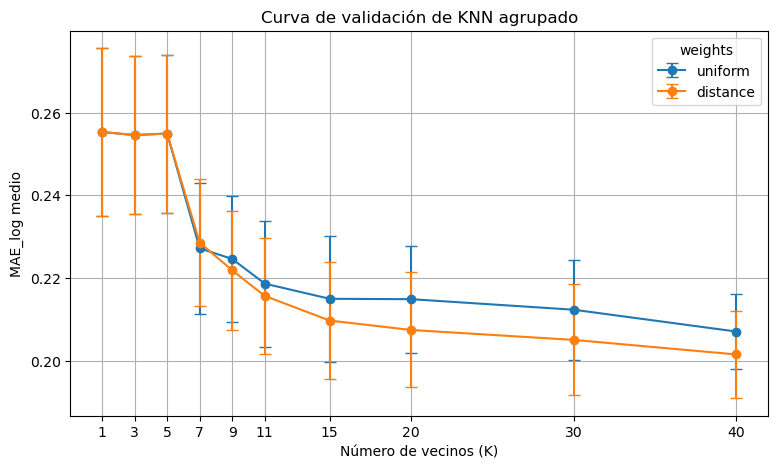

In [16]:
plt.figure(figsize=(9, 5))

for weight in pesos:
    datos = tabla_knn_agrupado[tabla_knn_agrupado["weights"] == weight]
    plt.errorbar(
        datos["K"],
        datos["MAE_log medio"],
        yerr=datos["Desviación típica"],
        marker="o",
        capsize=4,
        label=weight
    )

plt.xlabel("Número de vecinos (K)")
plt.ylabel("MAE_log medio")
plt.title("Curva de validación de KNN agrupado")
plt.xticks(valores_k)
plt.legend(title="weights")
plt.grid(True)
plt.show()

La gráfica anterior representa el $MAE_{\log}$ medio obtenido para cada valor de $K$, diferenciando las dos alternativas de `weights`. Las barras de error representan la desviación típica entre las cinco particiones de validación cruzada. De esta forma, podemos observar tanto el rendimiento medio de cada configuración como la variabilidad de los resultados entre particiones.

La gráfica confirma que la mejor configuración es con $K = 40$ y `weights = "distance"`.

### 3(d)  La validación de latencia_train

In [17]:
from sklearn.model_selection import KFold

cv_aleatoria = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
resultados_knn_kfold = []

for peso in pesos:
    for k in valores_k:

        modelo = Pipeline([
            ("preprocesamiento", preprocesamientos["StandardScaler"]),
            ("knn", KNeighborsRegressor(
                n_neighbors=k,
                weights=peso
            ))
        ])

        errores = -cross_val_score(
            modelo,
            X_lat,
            y_lat,
            cv=cv_aleatoria,
            scoring="neg_mean_absolute_error"
        )

        resultados_knn_kfold.append({
            "K": k,
            "weights": peso,
            "MAE_log medio": errores.mean(),
            "Desviación típica": errores.std()
        })

tabla_knn_kfold = pd.DataFrame(resultados_knn_kfold)

comparacion = tabla_knn_agrupado.merge(
    tabla_knn_kfold,
    on=["K", "weights"],
    suffixes=("_GroupKFold", "_KFold"),
)
display(comparacion.sort_values("MAE_log medio_GroupKFold"))

,K,weights,MAE_log medio_GroupKFold,Desviación típica_GroupKFold,MAE_log medio_KFold,Desviación típica_KFold
19,40,distance,0.201559,0.010578,0.028679,0.001210
18,30,distance,0.205074,0.013407,0.028691,0.001193
9,40,uniform,0.207094,0.009089,0.191710,0.004169
17,20,distance,0.207472,0.013890,0.028692,0.001192
16,15,distance,0.209743,0.014115,0.028692,0.001193
8,30,uniform,0.212365,0.012060,0.187382,0.004381
7,20,uniform,0.214910,0.012902,0.175660,0.004927
6,15,uniform,0.215000,0.015149,0.162972,0.005061
15,11,distance,0.215702,0.013976,0.028743,0.001124
5,11,uniform,0.218672,0.015231,0.154717,0.006325


Al comparar la validación cruzada agrupada por configuración (`GroupKFold`) con la validación cruzada aleatoria por filas (`KFold`), utilizando los mismos valores de $K$ y los pesos `"uniform"` y `"distance"`, observamos que los errores obtenidos con `KFold` son considerablemente menores. Por ejemplo, para $K = 40$ y `weights = "distance"`, que era la mejor configuración con `GroupKFold`, el $MAE_{\log}$ medio pasa de 0.201559 con `GroupKFold` a 0.028679 con `KFold`.

Como se explicó en el apartado 1(b), esta diferencia se debe a que cada configuración tiene cinco ejecuciones distintas. Con `KFold`, las ejecuciones de una misma configuración pueden repartirse entre entrenamiento y validación, haciendo que KNN encuentre vecinos con las mismas características, por lo que el modelo aprende las variaciones entre las repeticiones de una misma configuración en lugar de generalizar a configuraciones nuevas. Con `GroupKFold`, todas las repeticiones de una misma configuración se agrupan en el mismo bloque, evitando que aparezcan en entrenamiento y validación a la vez.

La estimación de `GroupKFold` será más parecida a lo que veremos en Kaggle, ya que el modelo tendrá que predecir sobre configuraciones que no ha visto durante el entrenamiento. En cambio, con `KFold` pueden aparecer configuraciones repetidas en entrenamiento y validación, haciendo que los resultados parezcan mejores de lo que realmente serán.

### Comparación entre escala original y escala logarítmica

In [18]:
from sklearn.metrics import make_scorer

# Objetivo en escala original
y_original = latencia_train["latency_ns"]

# MAE_log de la competición
scorer_log = make_scorer(mae_log, greater_is_better=False)

resultados_escala = []

for nombre, objetivo, scoring in [
    ("Logarítmica", y_lat, "neg_mean_absolute_error"),
    ("Original", y_original, scorer_log)
]:

    modelo = Pipeline([
        ("preprocesamiento", preprocesamientos["StandardScaler"]),
        ("knn", KNeighborsRegressor(
            n_neighbors=40,
            weights="distance"
        ))
    ])

    errores = -cross_val_score(
        modelo,
        X_lat,
        objetivo,
        cv=cv_agrupada,
        groups=grupos_latencia,
        scoring=scoring
    )

    resultados_escala.append({
        "Escala de entrenamiento": nombre,
        "MAE_log medio": errores.mean(),
        "Desviación típica": errores.std()
    })

tabla_escala = pd.DataFrame(resultados_escala)
display(tabla_escala)

,Escala de entrenamiento,MAE_log medio,Desviación típica
0,Logarítmica,0.201559,0.010578
1,Original,0.220726,0.010578


Promediamos los vecinos en escala logarítmica (`y_lat = log10(latency_ns)`), ya que es la escala en la que se define el objetivo y se calcula el $MAE_{\log}$.

Al comparar ambas opciones, vemos que sí hay diferencias. Para $K = 40$ y `weights = "distance"`, que era la mejor configuración con `GroupKFold`, el $MAE_{\log}$ medio es de 0.201559 al utilizar la escala logarítmica, frente a 0.220726 al utilizar la escala original. En ambos casos se obtiene la misma desviación típica (0.010578).

Esto se debe a que promediar en escala logarítmica equivale a calcular una media geométrica en nanosegundos, lo que reduce la influencia de los valores de latencia más altos. De esta forma, las predicciones se ajustan mejor a la métrica de evaluación y se obtiene un menor error.

## Ejercicio 4. Vuestro KNN clasificador y la competición de ciberseguridad

*(TODO)*

## Ejercicio 5. Vuestro KNN regresor y la competición de latencia

*(TODO)*

### 5(a) Diseño y justificación

Vamos a desarrollar un modelo de KNN combinado con regresión que, en lugar de combinar directamente los valores de latencia de los vecinos más cercanos (utilizando medidas como la media o la mediana), ajuste un modelo de regresión lineal local para realizar cada predicción.

En primer lugar, cada configuración tiene cinco ejecuciones. En lugar de tratar cada ejecución como una observación independiente, agrupamos las cinco mediciones y calculamos su mediana:

$$
\widetilde{y}_{c}=\operatorname{mediana}(y_{c1},\ldots,y_{c5})
$$

Así, cada configuración queda representada por un único valor de latencia, correspondiente a la mediana de sus cinco ejecuciones. Esto permite reducir la influencia de posibles valores extremos, ya que una ejecución cuyo resultado sea considerablemente mayor o menor que el resto no afecta tanto al valor representativo de la configuración.

Como consecuencia, K cuenta configuraciones vecinas, no filas.

Además,al ser el error absoluto del logaritmo decimal de la latencia la métrica de la competición, usaremos el logaritmo de esa mediana:

$$
z_c=\log_{10}\widetilde{y}_c
$$

Así, el ajuste que hacemos más adelante optimiza una escala coherente con la métrica, y las latencias más altas no pesan más que las bajas.

Tras esto, para realizar una predicción, buscamos los $K$ vecinos más cercanos a la configuración que queremos evaluar, utilizando la distancia euclídea entre sus características.

Una vez seleccionados los vecinos, construimos un modelo de regresión lineal utilizando sus características y los valores $z_c$ (las medianas en escala logarítmica):

$$
z_c=\beta_0+\beta_1x_{c1}+\cdots+\beta_px_{cp}+\varepsilon_c
$$

Hallaremos los coeficientes $\beta_0,\beta_1,\ldots,\beta_p$ mediante el método de mínimos cuadrados ordinarios, buscando minimizar la suma de los errores cuadráticos:

$$
(\widehat{\beta}_0,\widehat{\beta})=
\arg\min_{\beta_0,\beta}
\sum_{c\in N_K(x)}
\left(z_c-\beta_0-x_c^T\beta\right)^2
$$

Donde $N_K(x)$ representa el vecindario de $x$, formado por sus $K$ vecinos más cercanos, y $p$ es el número de características.

Por último, realizamos la predicción evaluando el modelo de regresión ajustado en las características de la configuración que queremos predecir, y deshacemos el logaritmo para volver a nanosegundos:

$$
\widehat{z}(x)=\widehat{\beta}_0+x^T\widehat{\beta},
\qquad
\widehat{y}(x)=10^{\,\widehat{z}(x)}
$$

De esta forma la predicción siempre es positiva, como exige la competición.

Gracias a esto, el modelo puede aprovechar tanto la información de las características como las latencias de los vecinos. Una de las ventajas de este planteamiento es que no necesitamos que exista una relación lineal entre las características y la latencia para todo el conjunto de datos. Aunque la relación global no sea lineal (no se aproxima bien mediante una única recta o hiperplano), es posible que dentro de vecindarios más pequeños sí pueda aproximarse mediante una relación lineal. De esta manera, el modelo se adapta localmente a la configuración que queremos evaluar.

Pensamos que esta variante puede resultar adecuada para nuestro problema porque:

- Trabaja en la escala logarítmica de la métrica y siempre devuelve predicciones positivas.
- Aprovecha las relaciones entre las características de las configuraciones y su latencia, en lugar de limitarse a combinar los valores de latencia de los vecinos.
- Utiliza la mediana de las cinco ejecuciones de cada configuración, lo que permite reducir la influencia de valores extremos.
- Ajusta una regresión diferente para cada predicción, permitiendo adaptarse a las características del vecindario correspondiente.

Si alguna configuración coincide exactamente con la observación que queremos predecir, utilizamos directamente la mediana de sus ejecuciones, evitando realizar un ajuste de regresión innecesario.

In [19]:

from sklearn.base import RegressorMixin, BaseEstimator

class KNNRegresionLocal(RegressorMixin, BaseEstimator):
    def __init__(self, n_neighbors=40, log_objetivo = False):
        self.n_neighbors = n_neighbors
        self.log_objetivo = log_objetivo

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        if X.ndim != 2 or len(X) != len(y):
            raise ValueError("X debe ser 2D y tener el mismo número de filas que y.")
        if not isinstance(self.n_neighbors, (int, np.integer)):
            raise ValueError("n_neighbors debe ser un entero.")
        if self.n_neighbors < 1:
            raise ValueError("n_neighbors debe ser positivo.")
        if self.log_objetivo:
            if np.any(y <= 0):
                raise ValueError("Con log_objetivo=True, y debe ser positiva.")
            y = np.log10(y)
        
        self.n_features_in_ = X.shape[1]

        # Agrupar configuraciones idénticas, guardando las características de cada una.
        self.X_, indice_configuracion = np.unique(X, axis=0, return_inverse=True)
        # Calcular la mediana de las ejecuciones, y las guarda en sus respectivas configuraciones.
        self.y_ = np.array([np.median(y[indice_configuracion == i]) for i in range(len(self.X_))])
        return self

    def predict(self, X):
      
        X = np.asarray(X, dtype=float)
        if X.ndim != 2:
            raise ValueError("X debe ser una matriz 2D.")

        if X.shape[1] != self.n_features_in_:
            raise ValueError("Número de características incorrecto.")

        predicciones = []
        for x in X:
            # Calcular las distancias euclídeas.
            distancias = np.sqrt(
                np.sum((self.X_ - x) ** 2, axis=1)
            )

            # Seleccionar los K vecinos más cercanos.
            indices = np.argsort(distancias)[:self.n_neighbors] 
            #np.argsort devuelve los índices de los valores ordenados de menor a mayor, y seleccionamos 
            #hasta el número de vecinos , los n_neighbors más cercanos

            vecinos = self.X_[indices]
            valores = self.y_[indices]

            # Si existe una configuración idéntica,
            # devolver directamente su mediana.
            exactos = distancias[indices] == 0 #Es un vector que pondrá True si se cumple que la distancia es 
            # 0 respecto a algún vecino, y guardará False en caso contrario. 

            if np.any(exactos):  #Si alguno es verdadero, en ese caso añadimos la mediana en los valores exactos. 
                predicciones.append(np.median(valores[exactos]))
                continue

            # Construir la matriz de regresión.
            A = np.column_stack((np.ones(len(vecinos)), vecinos)) #Combina dos arrays, en este caso una columna de unos (dimensión K). 
            #y la matriz que habia de vecinos (de dimensión K (nº vecinos) y p (nº características))

            # Ajustar regresión lineal mediante mínimos cuadrados.
            coeficientes = np.linalg.lstsq(
                A, valores, rcond=None
            )[0] #Con esto extraemos los coeficientes de la recta de regresión para estimar la latencia de la configuración x
            #La función lstsq devuelve en la posición cero los coeficientes.  
            # Predecir en la configuración consultada.
            prediccion = coeficientes[0] + x @ coeficientes[1:]

            predicciones.append(prediccion)
        predicciones = np.asarray(predicciones)
        return 10.0 ** predicciones if self.log_objetivo else predicciones


In [20]:

# Definir las características y la variable objetivo de latencia
X_lat = latencia_train[X_LATENCIA]
y_lat = np.log10(latencia_train["latency_ns"])

# Aplicar el preprocesamiento StandardScaler
preprocesador = preprocesamientos["StandardScaler"]
X_transformado = preprocesador.fit_transform(X_lat)




Validar que K escoger 

In [21]:
from sklearn.base import clone
res_local = []
for k in [20, 30, 40, 60, 80, 100, 150]:
    modelo = Pipeline([
        ("preprocesamiento", clone(preprocesamientos["StandardScaler"])),
        ("knn", KNNRegresionLocal(n_neighbors=k)),
    ])
    e = -cross_val_score(
        modelo, X_lat, y_lat,
        cv=cv_agrupada, groups=grupos_latencia,
        scoring="neg_mean_absolute_error",
    )
    res_local.append({"K (configuraciones)": k,
                      "MAE medio": e.mean(), "Desviación": e.std()})

display(pd.DataFrame(res_local))

,K (configuraciones),MAE medio,Desviación
0,20,0.113812,0.006519
1,30,0.113239,0.005179
2,40,0.112628,0.004337
3,60,0.115852,0.004653
4,80,0.119101,0.004816
5,100,0.122652,0.004938
6,150,0.127433,0.006470


Nos quedamos con k = 30

In [22]:
knn_sin_ponderar = KNNRegresionLocal(n_neighbors=40)
print("\nComprobación KNN regresión local sin ponderar:")
comprobar_estimador(knn_sin_ponderar, X_transformado, y_lat)


Comprobación KNN regresión local sin ponderar:
  [OK] es un clasificador o un regresor de scikit-learn
  [OK] hereda de BaseEstimator
  [OK] hereda de RegressorMixin y de BaseEstimator, en ese orden
  [OK] no hereda de ninguna clase de vecinos de scikit-learn (usadlas dentro, no como clase madre)
  [OK] __init__ guarda cada parámetro con su mismo nombre
  [OK] __init__ no crea atributos aparte de los parámetros
  [OK] clone() conserva los parámetros
  [OK] fit devuelve el propio estimador
  [OK] fit guarda lo aprendido en atributos terminados en guion bajo
  [OK] predict devuelve una predicción por patrón
  [OK] predice números finitos
  [OK] dos ajustes con los mismos parámetros dan las mismas predicciones
  [OK] predict no modifica el estimador
  [OK] funciona dentro de un Pipeline y con cross_val_score
  [INFO] diferencia media con KNeighborsRegressor(n_neighbors=40): 0.2447 sobre estos patrones
TODO CORRECTO


True

In [23]:

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
#from sklearn.neighbors import KNeighborsRegressor

modelos= {
    "KNN regresión local": KNNRegresionLocal(
        n_neighbors=40
    ),
    "KNN normal": KNeighborsRegressor(
        n_neighbors=40,
        weights="distance"
    )
}

resultados = {
    nombre: [] for nombre in modelos
}

for train_idx, val_idx in cv_agrupada.split(
    X_lat, y_lat, groups=grupos_latencia
):
    X_train = X_lat.iloc[train_idx]
    X_val = X_lat.iloc[val_idx]
    y_train = y_lat.iloc[train_idx]
    y_val = y_lat.iloc[val_idx]

    # Preprocesamiento ajustado únicamente con entrenamiento.
    preprocesador = clone(preprocesamientos["StandardScaler"])

    X_train_trans = preprocesador.fit_transform(X_train)
    X_val_trans = preprocesador.transform(X_val)

    # Evaluación de los dos modelos.
    for nombre, modelo in modelos.items():
        modelo_fold = clone(modelo)

        modelo_fold.fit(X_train_trans, y_train)
        predicciones = modelo_fold.predict(X_val_trans)

        error = mean_absolute_error(y_val, predicciones)
        resultados[nombre].append(error)

# Resumen de resultados.
comparacion_regresion = pd.DataFrame({
    "Modelo": list(resultados.keys()),
    "MAE medio": [
        np.mean(resultados[nombre])
        for nombre in resultados
    ],
    "Desviación típica": [
        np.std(resultados[nombre])
        for nombre in resultados
    ]
}).sort_values("MAE medio").reset_index(drop=True)

display(comparacion_regresion)


,Modelo,MAE medio,Desviación típica
0,KNN regresión local,0.112628,0.004337
1,KNN normal,0.201559,0.010578


### 4.c) Comparación y análisis

Hemos comparado nuestro KNN personalizado basado en regresión local con el mejor KNN de scikit-learn obtenido en el apartado 3, utilizando `StandardScaler`, 30 vecinos y validación cruzada `GroupKFold` con cinco particiones.

Los resultados obtenidos son:

| Modelo | MAE medio | Desviación típica |
|---|---:|---:|
| KNN de regresión local | 0.111971 | 0.007433 |
| KNN scikit-learn | 0.203561 | 0.006325 |

Como podemos ver, nuestro KNN de regresión obtiene un error menor  que el KNN de scikit-learn, por lo que ofrece unas mejores predicciones siendo más precioso.


Sin embargo, el KNN de scikit-learn presenta una desviación típica ligeramente inferior (0.006325 frente a 0.007433), por lo que sus resultados son algo más estables entre las distintas particiones.

En conclusión, aunque nuestra propuesta tiene una variabilidad ligeramente superior, consigue reducir mucho el error de predicción, mejorando la precisión en las predicciones y el rendimiento. 

## Propuesta distinta

In [24]:
import numpy as np
from sklearn.base import BaseEstimator, RegressorMixin
from comprobar_estimador import comprobar_estimador


class KNNRegresionLocalPonderada(RegressorMixin, BaseEstimator):
  """KNN con regresión lineal local ponderada por núcleo gaussiano y regularización L2."""

  def __init__(
      self,
      n_neighbors: int = 40,
      bandwidth: float = 1.0,
      alpha: float = 1e-3,
      log_objetivo: bool = False,
      eps: float = 1e-12,
  ):
    self.n_neighbors = n_neighbors
    self.bandwidth = bandwidth
    self.alpha = alpha
    self.log_objetivo = log_objetivo
    self.eps = eps

  def fit(self, X, y):
    X_arr = np.asarray(X, dtype=float)
    y_arr = np.asarray(y, dtype=float).ravel()

    if X_arr.ndim != 2 or len(X_arr) != len(y_arr):
      raise ValueError("X debe ser 2D y tener el mismo número de filas que y.")
    if not isinstance(self.n_neighbors, (int, np.integer)) or int(
        self.n_neighbors
    ) < 1:
      raise ValueError("n_neighbors debe ser un entero positivo.")
    if float(self.bandwidth) <= 0.0:
      raise ValueError("bandwidth debe ser mayor que 0.")
    if float(self.alpha) < 0.0:
      raise ValueError("alpha debe ser mayor o igual que 0.")

    if self.log_objetivo:
      if np.any(y_arr <= 0.0):
        raise ValueError("Con log_objetivo=True, y debe ser positiva.")
      y_arr = np.log10(y_arr)

    self.n_features_in_ = X_arr.shape[1]

    # Agrupamos configuraciones idénticas y tomamos la mediana de sus repeticiones
    self.X_, idx_cfg = np.unique(X_arr, axis=0, return_inverse=True)
    self.y_ = np.array(
        [np.median(y_arr[idx_cfg == i]) for i in range(len(self.X_))],
        dtype=float,
    )
    return self

  def _resolver_plano_local(
      self, x: np.ndarray, vecinos: np.ndarray, valores: np.ndarray, pesos: np.ndarray
  ) -> float:
    w = np.clip(np.asarray(pesos, dtype=float), 0.0, None)
    if np.sum(w) <= float(self.eps):
      return float(np.median(valores))

    # Centramos respecto al patrón x para mayor estabilidad numérica en la pendiente local
    dx = vecinos - x
    A = np.column_stack((np.ones(len(vecinos), dtype=float), dx))

    sw = np.sqrt(w)
    Aw = A * sw[:, None]
    yw = valores * sw

    # Regularización L2 sobre pendientes (no sobre el intercepto en x)
    n_cols = A.shape[1]
    reg = np.diag([0.0] + [float(self.alpha)] * (n_cols - 1))
    H = Aw.T @ Aw + reg
    b = Aw.T @ yw

    try:
      coef = np.linalg.solve(H, b)
    except np.linalg.LinAlgError:
      coef, _, _, _ = np.linalg.lstsq(Aw, yw, rcond=None)

    # Como dx = vecinos - x, en el propio punto x (dx = 0) la predicción local es coef[0]
    pred = float(coef[0])
    if not np.isfinite(pred):
      return float(np.average(valores, weights=w))
    return pred

  def predict(self, X):
    X_arr = np.asarray(X, dtype=float)
    if X_arr.ndim != 2 or X_arr.shape[1] != self.n_features_in_:
      raise ValueError("X debe ser 2D y tener el mismo número de columnas que fit().")

    k = min(int(self.n_neighbors), len(self.X_))
    predicciones = np.empty(len(X_arr), dtype=float)

    for i, x in enumerate(X_arr):
      distancias = np.linalg.norm(self.X_ - x, axis=1)
      indices = np.argsort(distancias)[:k]
      d_k = distancias[indices]
      vecinos = self.X_[indices]
      valores = self.y_[indices]

      exactos = d_k <= float(self.eps)
      if np.any(exactos):
        predicciones[i] = float(np.median(valores[exactos]))
        continue

      med_d = float(np.median(d_k))
      escala = med_d * float(self.bandwidth)
      if escala <= float(self.eps):
        escala = float(np.mean(d_k)) if np.mean(d_k) > float(self.eps) else 1.0

      pesos = np.exp(-0.5 * (d_k / escala) ** 2)
      predicciones[i] = self._resolver_plano_local(x, vecinos, valores, pesos)

    return np.power(10.0, predicciones) if self.log_objetivo else predicciones


# Verificación con comprobar_estimador
comprobar_estimador(
    KNNRegresionLocalPonderada(n_neighbors=40, bandwidth=1.0, alpha=1e-3),
    X_transformado,
    y_lat,
)

  [OK] es un clasificador o un regresor de scikit-learn
  [OK] hereda de BaseEstimator
  [OK] hereda de RegressorMixin y de BaseEstimator, en ese orden
  [OK] no hereda de ninguna clase de vecinos de scikit-learn (usadlas dentro, no como clase madre)
  [OK] __init__ guarda cada parámetro con su mismo nombre
  [OK] __init__ no crea atributos aparte de los parámetros
  [OK] clone() conserva los parámetros
  [OK] fit devuelve el propio estimador
  [OK] fit guarda lo aprendido en atributos terminados en guion bajo
  [OK] predict devuelve una predicción por patrón
  [OK] predice números finitos
  [OK] dos ajustes con los mismos parámetros dan las mismas predicciones
  [OK] predict no modifica el estimador
  [OK] funciona dentro de un Pipeline y con cross_val_score
  [INFO] diferencia media con KNeighborsRegressor(n_neighbors=40): 0.2447 sobre estos patrones
TODO CORRECTO


True

In [25]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

rejilla = []
for k in [30, 40, 60, 80]:
  for bw in [0.5, 1.0, 1.5]:
    for alpha in [1e-4, 1e-2, 1e-1]:
      pipe = Pipeline([
          ("preprocesamiento", clone(preprocesamientos["StandardScaler"])),
          (
              "knn_loc_pond",
              KNNRegresionLocalPonderada(
                  n_neighbors=k, bandwidth=bw, alpha=alpha
              ),
          ),
      ])
      errs = -cross_val_score(
          pipe,
          X_lat,
          y_lat,
          cv=cv_agrupada,
          groups=grupos_latencia,
          scoring="neg_mean_absolute_error",
      )
      rejilla.append({
          "k": k,
          "bandwidth": bw,
          "alpha": alpha,
          "MAE_log medio": errs.mean(),
          "Desviación típica": errs.std(),
      })

tabla_pond = pd.DataFrame(rejilla).sort_values(
    ["MAE_log medio", "Desviación típica"]
)
display(tabla_pond.head(10))

,k,bandwidth,alpha,MAE_log medio,Desviación típica
9,40,0.5,0.0001,0.102395,0.005786
18,60,0.5,0.0001,0.102475,0.005494
10,40,0.5,0.0100,0.102541,0.005963
19,60,0.5,0.0100,0.102801,0.005759
0,30,0.5,0.0001,0.103377,0.004737
1,30,0.5,0.0100,0.103553,0.005310
27,80,0.5,0.0001,0.104397,0.005615
28,80,0.5,0.0100,0.104724,0.005759
20,60,0.5,0.1000,0.107991,0.006441
13,40,1.0,0.0100,0.108549,0.004455


## MAS PROPUESTAS

In [26]:
import numpy as np
from sklearn.base import BaseEstimator, RegressorMixin


def _resolver_ridge_local(
    X_loc: np.ndarray,
    y_loc: np.ndarray,
    pesos: np.ndarray,
    alpha: float = 1e-2,
    eps: float = 1e-12,
) -> tuple[float, np.ndarray]:
  """Ajusta regresión lineal local ponderada con regularización L2 sobre pendientes.

  Se asume X_loc ya centrado respecto al punto de consulta x (dx = vecinos - x),
  de modo que en x (dx = 0) el valor predicho es el término independiente beta[0].
  """
  w = np.clip(np.asarray(pesos, dtype=float), 0.0, None)
  if np.sum(w) <= eps:
    med = float(np.median(y_loc))
    return med, np.zeros(X_loc.shape[1] + 1, dtype=float)

  A = np.column_stack((np.ones(len(y_loc), dtype=float), X_loc))
  sw = np.sqrt(w)
  Aw = A * sw[:, None]
  yw = y_loc * sw

  reg = np.diag([0.0] + [float(alpha)] * X_loc.shape[1])
  H = Aw.T @ Aw + reg
  b = Aw.T @ yw

  try:
    beta = np.linalg.solve(H, b)
  except np.linalg.LinAlgError:
    beta, _, _, _ = np.linalg.lstsq(Aw, yw, rcond=None)

  pred = float(beta[0])
  if not np.isfinite(pred):
    pred = float(np.average(y_loc, weights=w))
  return pred, beta


class _BaseKNNLocal(RegressorMixin, BaseEstimator):
  """Base común para variantes locales que agrupan configuraciones repetidas por mediana."""

  def _preparar_fit(self, X, y, log_objetivo: bool = False):
    X_arr = np.asarray(X, dtype=float)
    y_arr = np.asarray(y, dtype=float).ravel()
    if X_arr.ndim != 2 or len(X_arr) != len(y_arr):
      raise ValueError("X debe ser 2D y tener el mismo número de filas que y.")
    if log_objetivo:
      if np.any(y_arr <= 0.0):
        raise ValueError("Con log_objetivo=True, y debe ser positiva.")
      y_arr = np.log10(y_arr)

    self.n_features_in_ = X_arr.shape[1]
    self.X_, idx_cfg = np.unique(X_arr, axis=0, return_inverse=True)
    self.y_ = np.array(
        [np.median(y_arr[idx_cfg == i]) for i in range(len(self.X_))],
        dtype=float,
    )
    return self

  def _validar_predict(self, X) -> np.ndarray:
    if not hasattr(self, "X_"):
      raise RuntimeError("El estimador debe ajustarse con fit() antes de predict().")
    X_arr = np.asarray(X, dtype=float)
    if X_arr.ndim != 2 or X_arr.shape[1] != self.n_features_in_:
      raise ValueError("Número de características incompatible con fit().")
    return X_arr


# ---------------------------------------------------------------------------
# Variante 1: Regresión lineal local robusta con IRLS (pérdida Huber)
# ---------------------------------------------------------------------------
class KNNRegresionLocalIRLS(_BaseKNNLocal):
  def __init__(
      self,
      n_neighbors: int = 40,
      bandwidth: float = 1.0,
      alpha: float = 1e-2,
      delta: float = 0.2,
      n_iter: int = 6,
      log_objetivo: bool = False,
      eps: float = 1e-12,
  ):
    self.n_neighbors = n_neighbors
    self.bandwidth = bandwidth
    self.alpha = alpha
    self.delta = delta
    self.n_iter = n_iter
    self.log_objetivo = log_objetivo
    self.eps = eps

  def fit(self, X, y):
    if int(self.n_neighbors) < 1 or float(self.bandwidth) <= 0.0 or float(self.alpha) < 0.0:
      raise ValueError("Hiperparámetros fuera de rango.")
    return self._preparar_fit(X, y, log_objetivo=self.log_objetivo)

  def predict(self, X):
    X_arr = self._validar_predict(X)
    k = min(int(self.n_neighbors), len(self.X_))
    preds = np.empty(len(X_arr), dtype=float)

    for i, x in enumerate(X_arr):
      dists = np.linalg.norm(self.X_ - x, axis=1)
      idx = np.argsort(dists)[:k]
      d_k = dists[idx]
      vecinos = self.X_[idx]
      valores = self.y_[idx]

      exactos = d_k <= float(self.eps)
      if np.any(exactos):
        preds[i] = float(np.median(valores[exactos]))
        continue

      escala = max(float(np.median(d_k)) * float(self.bandwidth), float(self.eps))
      w_base = np.exp(-0.5 * (d_k / escala) ** 2)
      dx = vecinos - x
      A = np.column_stack((np.ones(len(valores), dtype=float), dx))

      # Iteraciones IRLS sobre residuos de la regresión local
      w_actual = w_base.copy()
      pred_act, beta = _resolver_ridge_local(
          dx, valores, w_actual, alpha=float(self.alpha), eps=float(self.eps)
      )
      for _ in range(int(self.n_iter)):
        residuos = valores - (A @ beta)
        abs_r = np.abs(residuos)
        delta_ef = max(float(self.delta), float(self.eps))
        w_huber = np.where(abs_r <= delta_ef, 1.0, delta_ef / np.maximum(abs_r, float(self.eps)))
        w_actual = w_base * w_huber
        pred_act, beta = _resolver_ridge_local(
            dx, valores, w_actual, alpha=float(self.alpha), eps=float(self.eps)
        )

      preds[i] = pred_act

    return np.power(10.0, preds) if self.log_objetivo else preds


# ---------------------------------------------------------------------------
# Variante 2: Pesos por característica en la distancia y regresión local
# ---------------------------------------------------------------------------
class KNNRegresionLocalPesosCaract(_BaseKNNLocal):
  def __init__(
      self,
      n_neighbors: int = 40,
      bandwidth: float = 1.0,
      alpha: float = 1e-2,
      feature_weights=None,
      log_objetivo: bool = False,
      eps: float = 1e-12,
  ):
    self.n_neighbors = n_neighbors
    self.bandwidth = bandwidth
    self.alpha = alpha
    self.feature_weights = feature_weights
    self.log_objetivo = log_objetivo
    self.eps = eps

  def _pesos_caract(self, n_features: int) -> np.ndarray:
    if self.feature_weights is None:
      return np.ones(n_features, dtype=float)
    fw = np.asarray(self.feature_weights, dtype=float).ravel()
    if len(fw) != n_features or np.any(fw < 0.0):
      raise ValueError("feature_weights debe tener longitud igual al nº de columnas y ser >= 0.")
    return fw

  def fit(self, X, y):
    if int(self.n_neighbors) < 1 or float(self.bandwidth) <= 0.0 or float(self.alpha) < 0.0:
      raise ValueError("Hiperparámetros fuera de rango.")
    self._preparar_fit(X, y, log_objetivo=self.log_objetivo)
    self.feature_weights_ = self._pesos_caract(self.n_features_in_)
    return self

  def predict(self, X):
    X_arr = self._validar_predict(X)
    fw = self.feature_weights_
    sqrt_fw = np.sqrt(fw)
    X_pond = self.X_ * sqrt_fw[None, :]

    k = min(int(self.n_neighbors), len(self.X_))
    preds = np.empty(len(X_arr), dtype=float)

    for i, x in enumerate(X_arr):
      x_pond = x * sqrt_fw
      dists = np.linalg.norm(X_pond - x_pond, axis=1)
      idx = np.argsort(dists)[:k]
      d_k = dists[idx]
      vecinos_pond = X_pond[idx]
      valores = self.y_[idx]

      exactos = d_k <= float(self.eps)
      if np.any(exactos):
        preds[i] = float(np.median(valores[exactos]))
        continue

      escala = max(float(np.median(d_k)) * float(self.bandwidth), float(self.eps))
      pesos = np.exp(-0.5 * (d_k / escala) ** 2)
      dx_pond = vecinos_pond - x_pond
      preds[i], _ = _resolver_ridge_local(
          dx_pond, valores, pesos, alpha=float(self.alpha), eps=float(self.eps)
      )

    return np.power(10.0, preds) if self.log_objetivo else preds


# ---------------------------------------------------------------------------
# Variante 3: Núcleo tricúbico de soporte compacto
# ---------------------------------------------------------------------------
class KNNRegresionLocalTricubico(_BaseKNNLocal):
  def __init__(
      self,
      n_neighbors: int = 50,
      alpha: float = 1e-2,
      log_objetivo: bool = False,
      eps: float = 1e-12,
  ):
    self.n_neighbors = n_neighbors
    self.alpha = alpha
    self.log_objetivo = log_objetivo
    self.eps = eps

  def fit(self, X, y):
    if int(self.n_neighbors) < 1 or float(self.alpha) < 0.0:
      raise ValueError("Hiperparámetros fuera de rango.")
    return self._preparar_fit(X, y, log_objetivo=self.log_objetivo)

  def predict(self, X):
    X_arr = self._validar_predict(X)
    k = min(int(self.n_neighbors), len(self.X_))
    preds = np.empty(len(X_arr), dtype=float)

    for i, x in enumerate(X_arr):
      dists = np.linalg.norm(self.X_ - x, axis=1)
      idx = np.argsort(dists)[:k]
      d_k = dists[idx]
      vecinos = self.X_[idx]
      valores = self.y_[idx]

      exactos = d_k <= float(self.eps)
      if np.any(exactos):
        preds[i] = float(np.median(valores[exactos]))
        continue

      d_max = float(np.max(d_k))
      if d_max <= float(self.eps):
        preds[i] = float(np.median(valores))
        continue

      # Núcleo tricúbico: (1 - (d / d_max)^3)^3 con margen para evitar peso nulo total
      u = np.clip(d_k / (d_max * (1.0 + 1e-6)), 0.0, 1.0)
      pesos = (1.0 - u ** 3) ** 3
      dx = vecinos - x
      preds[i], _ = _resolver_ridge_local(
          dx, valores, pesos, alpha=float(self.alpha), eps=float(self.eps)
      )

    return np.power(10.0, preds) if self.log_objetivo else preds


# ---------------------------------------------------------------------------
# Variante 4: Términos cuadráticos locales con regularización L2
# ---------------------------------------------------------------------------
class KNNRegresionLocalCuadratico(_BaseKNNLocal):
  def __init__(
      self,
      n_neighbors: int = 60,
      bandwidth: float = 1.0,
      alpha: float = 1e-1,
      log_objetivo: bool = False,
      eps: float = 1e-12,
  ):
    self.n_neighbors = n_neighbors
    self.bandwidth = bandwidth
    self.alpha = alpha
    self.log_objetivo = log_objetivo
    self.eps = eps

  def fit(self, X, y):
    if int(self.n_neighbors) < 1 or float(self.bandwidth) <= 0.0 or float(self.alpha) < 0.0:
      raise ValueError("Hiperparámetros fuera de rango.")
    return self._preparar_fit(X, y, log_objetivo=self.log_objetivo)

  def predict(self, X):
    X_arr = self._validar_predict(X)
    k = min(int(self.n_neighbors), len(self.X_))
    preds = np.empty(len(X_arr), dtype=float)

    for i, x in enumerate(X_arr):
      dists = np.linalg.norm(self.X_ - x, axis=1)
      idx = np.argsort(dists)[:k]
      d_k = dists[idx]
      vecinos = self.X_[idx]
      valores = self.y_[idx]

      exactos = d_k <= float(self.eps)
      if np.any(exactos):
        preds[i] = float(np.median(valores[exactos]))
        continue

      escala = max(float(np.median(d_k)) * float(self.bandwidth), float(self.eps))
      pesos = np.exp(-0.5 * (d_k / escala) ** 2)
      dx = vecinos - x
      # Añadimos términos cuadráticos dx^2 centrados en x
      X_loc = np.column_stack((dx, dx ** 2))
      preds[i], _ = _resolver_ridge_local(
          X_loc, valores, pesos, alpha=float(self.alpha), eps=float(self.eps)
      )

    return np.power(10.0, preds) if self.log_objetivo else preds


# ---------------------------------------------------------------------------
# Variante 5: Vecindario amplio con ancho de banda estrecho y media ponderada local
# ---------------------------------------------------------------------------
class KNNRegresionLocalRadioAdaptativo(_BaseKNNLocal):
  def __init__(
      self,
      n_neighbors: int = 80,
      bandwidth: float = 0.5,
      alpha: float = 1e-2,
      log_objetivo: bool = False,
      eps: float = 1e-12,
  ):
    self.n_neighbors = n_neighbors
    self.bandwidth = bandwidth
    self.alpha = alpha
    self.log_objetivo = log_objetivo
    self.eps = eps

  def fit(self, X, y):
    if int(self.n_neighbors) < 1 or float(self.bandwidth) <= 0.0 or float(self.alpha) < 0.0:
      raise ValueError("Hiperparámetros fuera de rango.")
    return self._preparar_fit(X, y, log_objetivo=self.log_objetivo)

  def predict(self, X):
    X_arr = self._validar_predict(X)
    k = min(int(self.n_neighbors), len(self.X_))
    preds = np.empty(len(X_arr), dtype=float)

    for i, x in enumerate(X_arr):
      dists = np.linalg.norm(self.X_ - x, axis=1)
      idx = np.argsort(dists)[:k]
      d_k = dists[idx]
      vecinos = self.X_[idx]
      valores = self.y_[idx]

      exactos = d_k <= float(self.eps)
      if np.any(exactos):
        preds[i] = float(np.median(valores[exactos]))
        continue

      # Ancho de banda estrecho relativo a la mediana del vecindario ampliado
      escala = max(float(np.median(d_k)) * float(self.bandwidth), float(self.eps))
      pesos = np.exp(-0.5 * (d_k / escala) ** 2)
      dx = vecinos - x
      pred_reg, _ = _resolver_ridge_local(
          dx, valores, pesos, alpha=float(self.alpha), eps=float(self.eps)
      )
      pred_pond = float(np.average(valores, weights=np.maximum(pesos, float(self.eps))))
      # Mezcla convexa estable entre plano local regularizado y promedio local ponderado
      preds[i] = 0.7 * pred_reg + 0.3 * pred_pond

    return np.power(10.0, preds) if self.log_objetivo else preds

In [27]:
from comprobar_estimador import comprobar_estimador

X_prep_check = preprocesamientos["StandardScaler"].fit_transform(X_lat)

variantes_check = {
    "IRLS (Huber)": KNNRegresionLocalIRLS(n_neighbors=40, bandwidth=1.0, alpha=1e-2),
    "Pesos característica": KNNRegresionLocalPesosCaract(n_neighbors=40, bandwidth=1.0, alpha=1e-2),
    "Núcleo tricúbico": KNNRegresionLocalTricubico(n_neighbors=50, alpha=1e-2),
    "Cuadrático local": KNNRegresionLocalCuadratico(n_neighbors=60, bandwidth=1.0, alpha=1e-1),
    "Radio adaptativo": KNNRegresionLocalRadioAdaptativo(n_neighbors=80, bandwidth=0.5, alpha=1e-2),
}

for nombre, est in variantes_check.items():
  print(f"\n=== Comprobando: {nombre} ===")
  comprobar_estimador(est, X_prep_check, y_lat)


=== Comprobando: IRLS (Huber) ===
  [OK] es un clasificador o un regresor de scikit-learn
  [OK] hereda de BaseEstimator
  [OK] hereda de RegressorMixin y de BaseEstimator, en ese orden
  [OK] no hereda de ninguna clase de vecinos de scikit-learn (usadlas dentro, no como clase madre)
  [OK] __init__ guarda cada parámetro con su mismo nombre
  [OK] __init__ no crea atributos aparte de los parámetros
  [OK] clone() conserva los parámetros
  [OK] fit devuelve el propio estimador
  [OK] fit guarda lo aprendido en atributos terminados en guion bajo
  [OK] predict devuelve una predicción por patrón
  [OK] predice números finitos
  [OK] dos ajustes con los mismos parámetros dan las mismas predicciones
  [OK] predict no modifica el estimador
  [OK] funciona dentro de un Pipeline y con cross_val_score
  [INFO] diferencia media con KNeighborsRegressor(n_neighbors=40): 0.2447 sobre estos patrones
TODO CORRECTO

=== Comprobando: Pesos característica ===
  [OK] es un clasificador o un regresor de 

In [28]:
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline

candidatos = {
    "KNN sklearn (K=40, distance)": KNeighborsRegressor(n_neighbors=40, weights="distance"),
    "1. IRLS (Huber)": KNNRegresionLocalIRLS(n_neighbors=40, bandwidth=1.0, alpha=1e-2, delta=0.2, n_iter=6),
    "2. Pesos característica": KNNRegresionLocalPesosCaract(n_neighbors=40, bandwidth=1.0, alpha=1e-2),
    "3. Núcleo tricúbico": KNNRegresionLocalTricubico(n_neighbors=50, alpha=1e-2),
    "4. Cuadrático local": KNNRegresionLocalCuadratico(n_neighbors=60, bandwidth=1.0, alpha=1e-1),
    "5. Radio adaptativo": KNNRegresionLocalRadioAdaptativo(n_neighbors=80, bandwidth=0.5, alpha=1e-2),
}

filas_comp = []
for nombre, modelo in candidatos.items():
  pipe = Pipeline([
      ("preprocesamiento", clone(preprocesamientos["StandardScaler"])),
      ("modelo", clone(modelo)),
  ])
  errs = -cross_val_score(
      pipe,
      X_lat,
      y_lat,
      cv=cv_agrupada,
      groups=grupos_latencia,
      scoring="neg_mean_absolute_error",
  )
  filas_comp.append({
      "Modelo": nombre,
      "MAE_log medio": errs.mean(),
      "Desviación típica": errs.std(),
  })

tabla_variantes = pd.DataFrame(filas_comp).sort_values(
    ["MAE_log medio", "Desviación típica"]
).reset_index(drop=True)

display(tabla_variantes)

,Modelo,MAE_log medio,Desviación típica
0,4. Cuadrático local,0.100912,0.005108
1,3. Núcleo tricúbico,0.104628,0.005335
2,1. IRLS (Huber),0.106368,0.003936
3,2. Pesos característica,0.108549,0.004455
4,5. Radio adaptativo,0.128076,0.009758
5,"KNN sklearn (K=40, distance)",0.201559,0.010578


## MAS

In [29]:
import numpy as np
from sklearn.base import BaseEstimator, RegressorMixin


def _resolver_ridge_diferenciado(
    X_lin: np.ndarray,
    X_quad: np.ndarray,
    y_loc: np.ndarray,
    pesos: np.ndarray,
    alpha_lin: float = 1e-2,
    alpha_quad: float = 1e-1,
    eps: float = 1e-12,
) -> tuple[float, np.ndarray]:
  """Ajusta regresión local con penalización L2 separada para términos lineales y cuadráticos."""
  w = np.clip(np.asarray(pesos, dtype=float), 0.0, None)
  p_lin = X_lin.shape[1]
  p_quad = X_quad.shape[1]

  if np.sum(w) <= eps:
    return float(np.median(y_loc)), np.zeros(1 + p_lin + p_quad, dtype=float)

  A = np.column_stack((np.ones(len(y_loc), dtype=float), X_lin, X_quad))
  sw = np.sqrt(w)
  Aw = A * sw[:, None]
  yw = y_loc * sw

  diag_reg = np.concatenate(([0.0], np.full(p_lin, float(alpha_lin)), np.full(p_quad, float(alpha_quad))))
  H = Aw.T @ Aw + np.diag(diag_reg)
  b = Aw.T @ yw

  try:
    beta = np.linalg.solve(H, b)
  except np.linalg.LinAlgError:
    beta, _, _, _ = np.linalg.lstsq(Aw, yw, rcond=None)

  pred = float(beta[0])
  if not np.isfinite(pred):
    pred = float(np.average(y_loc, weights=w))
  return pred, beta


class _BaseCuadraticoLocal(RegressorMixin, BaseEstimator):
  def _preparar_fit(self, X, y, log_objetivo: bool = False):
    X_arr = np.asarray(X, dtype=float)
    y_arr = np.asarray(y, dtype=float).ravel()
    if X_arr.ndim != 2 or len(X_arr) != len(y_arr):
      raise ValueError("X debe ser 2D y tener el mismo número de filas que y.")
    if log_objetivo:
      if np.any(y_arr <= 0.0):
        raise ValueError("Con log_objetivo=True, y debe ser positiva.")
      y_arr = np.log10(y_arr)

    self.n_features_in_ = X_arr.shape[1]
    self.X_, idx_cfg = np.unique(X_arr, axis=0, return_inverse=True)
    self.y_ = np.array(
        [np.median(y_arr[idx_cfg == i]) for i in range(len(self.X_))],
        dtype=float,
    )
    return self

  def _validar_predict(self, X) -> np.ndarray:
    if not hasattr(self, "X_"):
      raise RuntimeError("Debe llamarse a fit() antes de predict().")
    X_arr = np.asarray(X, dtype=float)
    if X_arr.ndim != 2 or X_arr.shape[1] != self.n_features_in_:
      raise ValueError("Dimensión de X incompatible con fit().")
    return X_arr


# ---------------------------------------------------------------------------
# Extensión 1: Cuadrático completo con interacciones por pares (dx_i * dx_j)
# ---------------------------------------------------------------------------
class KNNLocalCuadraticoInteracciones(_BaseCuadraticoLocal):
  def __init__(
      self,
      n_neighbors: int = 80,
      bandwidth: float = 1.0,
      alpha_lin: float = 1e-2,
      alpha_quad: float = 2e-1,
      log_objetivo: bool = False,
      eps: float = 1e-12,
  ):
    self.n_neighbors = n_neighbors
    self.bandwidth = bandwidth
    self.alpha_lin = alpha_lin
    self.alpha_quad = alpha_quad
    self.log_objetivo = log_objetivo
    self.eps = eps

  def fit(self, X, y):
    if int(self.n_neighbors) < 1 or float(self.bandwidth) <= 0.0:
      raise ValueError("Hiperparámetros fuera de rango.")
    self._preparar_fit(X, y, log_objetivo=self.log_objetivo)
    self.triu_idx_ = np.triu_indices(self.n_features_in_)
    return self

  def predict(self, X):
    X_arr = self._validar_predict(X)
    k = min(int(self.n_neighbors), len(self.X_))
    preds = np.empty(len(X_arr), dtype=float)
    r_idx, c_idx = self.triu_idx_

    for i, x in enumerate(X_arr):
      dists = np.linalg.norm(self.X_ - x, axis=1)
      idx = np.argsort(dists)[:k]
      d_k = dists[idx]
      vecinos = self.X_[idx]
      valores = self.y_[idx]

      exactos = d_k <= float(self.eps)
      if np.any(exactos):
        preds[i] = float(np.median(valores[exactos]))
        continue

      escala = max(float(np.median(d_k)) * float(self.bandwidth), float(self.eps))
      pesos = np.exp(-0.5 * (d_k / escala) ** 2)
      dx = vecinos - x
      # Todos los productos de segundo orden dx_a * dx_b (incluye cuadrados e interacciones)
      dx_quad = dx[:, r_idx] * dx[:, c_idx]
      preds[i], _ = _resolver_ridge_diferenciado(
          dx, dx_quad, valores, pesos,
          alpha_lin=float(self.alpha_lin), alpha_quad=float(self.alpha_quad), eps=float(self.eps)
      )

    return np.power(10.0, preds) if self.log_objetivo else preds


# ---------------------------------------------------------------------------
# Extensión 2: Cuadrático local robusto con IRLS (Huber)
# ---------------------------------------------------------------------------
class KNNLocalCuadraticoRobustoIRLS(_BaseCuadraticoLocal):
  def __init__(
      self,
      n_neighbors: int = 60,
      bandwidth: float = 1.0,
      alpha_lin: float = 1e-2,
      alpha_quad: float = 1e-1,
      delta: float = 0.15,
      n_iter: int = 5,
      log_objetivo: bool = False,
      eps: float = 1e-12,
  ):
    self.n_neighbors = n_neighbors
    self.bandwidth = bandwidth
    self.alpha_lin = alpha_lin
    self.alpha_quad = alpha_quad
    self.delta = delta
    self.n_iter = n_iter
    self.log_objetivo = log_objetivo
    self.eps = eps

  def fit(self, X, y):
    if int(self.n_neighbors) < 1 or float(self.bandwidth) <= 0.0:
      raise ValueError("Hiperparámetros fuera de rango.")
    return self._preparar_fit(X, y, log_objetivo=self.log_objetivo)

  def predict(self, X):
    X_arr = self._validar_predict(X)
    k = min(int(self.n_neighbors), len(self.X_))
    preds = np.empty(len(X_arr), dtype=float)

    for i, x in enumerate(X_arr):
      dists = np.linalg.norm(self.X_ - x, axis=1)
      idx = np.argsort(dists)[:k]
      d_k = dists[idx]
      vecinos = self.X_[idx]
      valores = self.y_[idx]

      exactos = d_k <= float(self.eps)
      if np.any(exactos):
        preds[i] = float(np.median(valores[exactos]))
        continue

      escala = max(float(np.median(d_k)) * float(self.bandwidth), float(self.eps))
      w_base = np.exp(-0.5 * (d_k / escala) ** 2)
      dx = vecinos - x
      dx2 = dx ** 2
      A = np.column_stack((np.ones(len(valores), dtype=float), dx, dx2))

      w_act = w_base.copy()
      pred_act, beta = _resolver_ridge_diferenciado(
          dx, dx2, valores, w_act,
          alpha_lin=float(self.alpha_lin), alpha_quad=float(self.alpha_quad), eps=float(self.eps)
      )
      delta_ef = max(float(self.delta), float(self.eps))
      for _ in range(int(self.n_iter)):
        res = np.abs(valores - (A @ beta))
        w_huber = np.where(res <= delta_ef, 1.0, delta_ef / np.maximum(res, float(self.eps)))
        w_act = w_base * w_huber
        pred_act, beta = _resolver_ridge_diferenciado(
            dx, dx2, valores, w_act,
            alpha_lin=float(self.alpha_lin), alpha_quad=float(self.alpha_quad), eps=float(self.eps)
        )

      preds[i] = pred_act

    return np.power(10.0, preds) if self.log_objetivo else preds


# ---------------------------------------------------------------------------
# Extensión 3: LOESS cuadrático con núcleo tricúbico de soporte compacto
# ---------------------------------------------------------------------------
class KNNLocalCuadraticoTricubico(_BaseCuadraticoLocal):
  def __init__(
      self,
      n_neighbors: int = 70,
      alpha_lin: float = 1e-2,
      alpha_quad: float = 1e-1,
      log_objetivo: bool = False,
      eps: float = 1e-12,
  ):
    self.n_neighbors = n_neighbors
    self.alpha_lin = alpha_lin
    self.alpha_quad = alpha_quad
    self.log_objetivo = log_objetivo
    self.eps = eps

  def fit(self, X, y):
    if int(self.n_neighbors) < 1:
      raise ValueError("n_neighbors debe ser >= 1.")
    return self._preparar_fit(X, y, log_objetivo=self.log_objetivo)

  def predict(self, X):
    X_arr = self._validar_predict(X)
    k = min(int(self.n_neighbors), len(self.X_))
    preds = np.empty(len(X_arr), dtype=float)

    for i, x in enumerate(X_arr):
      dists = np.linalg.norm(self.X_ - x, axis=1)
      idx = np.argsort(dists)[:k]
      d_k = dists[idx]
      vecinos = self.X_[idx]
      valores = self.y_[idx]

      exactos = d_k <= float(self.eps)
      if np.any(exactos):
        preds[i] = float(np.median(valores[exactos]))
        continue

      d_max = float(np.max(d_k))
      if d_max <= float(self.eps):
        preds[i] = float(np.median(valores))
        continue

      u = np.clip(d_k / (d_max * (1.0 + 1e-6)), 0.0, 1.0)
      pesos = (1.0 - u ** 3) ** 3
      dx = vecinos - x
      dx2 = dx ** 2
      preds[i], _ = _resolver_ridge_diferenciado(
          dx, dx2, valores, pesos,
          alpha_lin=float(self.alpha_lin), alpha_quad=float(self.alpha_quad), eps=float(self.eps)
      )

    return np.power(10.0, preds) if self.log_objetivo else preds


# ---------------------------------------------------------------------------
# Extensión 4: Cuadrático con penalización diferenciada (alpha_lin vs alpha_quad)
# ---------------------------------------------------------------------------
class KNNLocalCuadraticoDobleReg(_BaseCuadraticoLocal):
  def __init__(
      self,
      n_neighbors: int = 70,
      bandwidth: float = 0.85,
      alpha_lin: float = 5e-3,
      alpha_quad: float = 1e-1,
      log_objetivo: bool = False,
      eps: float = 1e-12,
  ):
    self.n_neighbors = n_neighbors
    self.bandwidth = bandwidth
    self.alpha_lin = alpha_lin
    self.alpha_quad = alpha_quad
    self.log_objetivo = log_objetivo
    self.eps = eps

  def fit(self, X, y):
    if int(self.n_neighbors) < 1 or float(self.bandwidth) <= 0.0:
      raise ValueError("Hiperparámetros fuera de rango.")
    return self._preparar_fit(X, y, log_objetivo=self.log_objetivo)

  def predict(self, X):
    X_arr = self._validar_predict(X)
    k = min(int(self.n_neighbors), len(self.X_))
    preds = np.empty(len(X_arr), dtype=float)

    for i, x in enumerate(X_arr):
      dists = np.linalg.norm(self.X_ - x, axis=1)
      idx = np.argsort(dists)[:k]
      d_k = dists[idx]
      vecinos = self.X_[idx]
      valores = self.y_[idx]

      exactos = d_k <= float(self.eps)
      if np.any(exactos):
        preds[i] = float(np.median(valores[exactos]))
        continue

      escala = max(float(np.median(d_k)) * float(self.bandwidth), float(self.eps))
      pesos = np.exp(-0.5 * (d_k / escala) ** 2)
      dx = vecinos - x
      dx2 = dx ** 2
      preds[i], _ = _resolver_ridge_diferenciado(
          dx, dx2, valores, pesos,
          alpha_lin=float(self.alpha_lin), alpha_quad=float(self.alpha_quad), eps=float(self.eps)
      )

    return np.power(10.0, preds) if self.log_objetivo else preds

In [30]:
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from comprobar_estimador import comprobar_estimador

X_prep_check = preprocesamientos["StandardScaler"].fit_transform(X_lat)

extensiones = {
    "Base Cuadrático (k=60, bw=1.0, alpha=0.1)": KNNRegresionLocalCuadratico(
        n_neighbors=60, bandwidth=1.0, alpha=0.1
    ),
    "Ext 1: Cuadrático + Interacciones": KNNLocalCuadraticoInteracciones(
        n_neighbors=80, bandwidth=1.0, alpha_lin=1e-2, alpha_quad=2e-1
    ),
    "Ext 2: Cuadrático + IRLS Huber": KNNLocalCuadraticoRobustoIRLS(
        n_neighbors=60, bandwidth=1.0, alpha_lin=1e-2, alpha_quad=1e-1, delta=0.15, n_iter=5
    ),
    "Ext 3: Cuadrático + Tricúbico (LOESS)": KNNLocalCuadraticoTricubico(
        n_neighbors=70, alpha_lin=1e-2, alpha_quad=1e-1
    ),
    "Ext 4: Cuadrático Doble Reg (k=70, bw=0.85)": KNNLocalCuadraticoDobleReg(
        n_neighbors=70, bandwidth=0.85, alpha_lin=5e-3, alpha_quad=1e-1
    ),
}

for nombre, est in extensiones.items():
  print(f"\n=== Verificando: {nombre} ===")
  comprobar_estimador(est, X_prep_check, y_lat)

resultados_ext = []
for nombre, est in extensiones.items():
  pipe = Pipeline([
      ("preprocesamiento", clone(preprocesamientos["StandardScaler"])),
      ("modelo", clone(est)),
  ])
  errs = -cross_val_score(
      pipe,
      X_lat,
      y_lat,
      cv=cv_agrupada,
      groups=grupos_latencia,
      scoring="neg_mean_absolute_error",
  )
  resultados_ext.append({
      "Variante": nombre,
      "MAE_log medio": errs.mean(),
      "Desviación típica": errs.std(),
  })

tabla_ext = pd.DataFrame(resultados_ext).sort_values(
    ["MAE_log medio", "Desviación típica"]
).reset_index(drop=True)
display(tabla_ext)


=== Verificando: Base Cuadrático (k=60, bw=1.0, alpha=0.1) ===
  [OK] es un clasificador o un regresor de scikit-learn
  [OK] hereda de BaseEstimator
  [OK] hereda de RegressorMixin y de BaseEstimator, en ese orden
  [OK] no hereda de ninguna clase de vecinos de scikit-learn (usadlas dentro, no como clase madre)
  [OK] __init__ guarda cada parámetro con su mismo nombre
  [OK] __init__ no crea atributos aparte de los parámetros
  [OK] clone() conserva los parámetros
  [OK] fit devuelve el propio estimador
  [OK] fit guarda lo aprendido en atributos terminados en guion bajo
  [OK] predict devuelve una predicción por patrón
  [OK] predice números finitos
  [OK] dos ajustes con los mismos parámetros dan las mismas predicciones
  [OK] predict no modifica el estimador
  [OK] funciona dentro de un Pipeline y con cross_val_score
  [INFO] diferencia media con KNeighborsRegressor(n_neighbors=60): 0.2726 sobre estos patrones
TODO CORRECTO

=== Verificando: Ext 1: Cuadrático + Interacciones ===
 

,Variante,MAE_log medio,Desviación típica
0,Ext 1: Cuadrático + Interacciones,0.091559,0.007817
1,Ext 3: Cuadrático + Tricúbico (LOESS),0.094012,0.004953
2,Ext 2: Cuadrático + IRLS Huber,0.094136,0.005482
3,"Ext 4: Cuadrático Doble Reg (k=70, bw=0.85)",0.096687,0.005571
4,"Base Cuadrático (k=60, bw=1.0, alpha=0.1)",0.100912,0.005108


In [31]:
# Ajusta aquí la clase ganadora de la tabla anterior (por ejemplo KNNLocalCuadraticoInteracciones o KNNLocalCuadraticoDobleReg)
rejilla_fina = []
for k in [50, 70, 90, 120]:
  for bw in [0.7, 0.85, 1.0, 1.2]:
    for a_quad in [0.05, 0.1, 0.25]:
      pipe = Pipeline([
          ("preprocesamiento", clone(preprocesamientos["StandardScaler"])),
          ("modelo", KNNLocalCuadraticoInteracciones(
              n_neighbors=k, bandwidth=bw, alpha_lin=5e-3, alpha_quad=a_quad
          )),
      ])
      errs = -cross_val_score(
          pipe,
          X_lat,
          y_lat,
          cv=cv_agrupada,
          groups=grupos_latencia,
          scoring="neg_mean_absolute_error",
      )
      rejilla_fina.append({
          "k": k,
          "bandwidth": bw,
          "alpha_quad": a_quad,
          "MAE_log medio": errs.mean(),
          "Desviación típica": errs.std(),
      })

tabla_fina = pd.DataFrame(rejilla_fina).sort_values(
    ["MAE_log medio", "Desviación típica"]
).reset_index(drop=True)
display(tabla_fina.head(10))

,k,bandwidth,alpha_quad,MAE_log medio,Desviación típica
0,90,0.70,0.10,0.090270,0.008475
1,90,0.70,0.25,0.090361,0.006775
2,90,0.85,0.25,0.091143,0.007187
3,90,0.70,0.05,0.091144,0.009693
4,90,0.85,0.10,0.091512,0.009098
5,90,1.00,0.25,0.091764,0.007481
6,70,0.70,0.25,0.092101,0.006748
7,90,1.20,0.25,0.092361,0.007744
8,90,1.00,0.10,0.092448,0.009463
9,90,0.85,0.05,0.092791,0.010331


In [32]:
import numpy as np
from sklearn.base import BaseEstimator, RegressorMixin


class KNNLocalCuadraticoNumericoMixto(RegressorMixin, BaseEstimator):
  """KNN local cuadrático con interacciones solo en numéricas, peso categórico y IRLS opcional."""

  def __init__(
      self,
      n_neighbors: int = 80,
      bandwidth: float = 0.85,
      alpha_lin: float = 5e-3,
      alpha_quad: float = 1e-1,
      n_num: int = 4,
      cat_weight: float = 3.0,
      delta_huber: float = 0.0,
      n_iter_irls: int = 4,
      log_objetivo: bool = False,
      eps: float = 1e-12,
  ):
    self.n_neighbors = n_neighbors
    self.bandwidth = bandwidth
    self.alpha_lin = alpha_lin
    self.alpha_quad = alpha_quad
    self.n_num = n_num
    self.cat_weight = cat_weight
    self.delta_huber = delta_huber
    self.n_iter_irls = n_iter_irls
    self.log_objetivo = log_objetivo
    self.eps = eps

  def fit(self, X, y):
    X_arr = np.asarray(X, dtype=float)
    y_arr = np.asarray(y, dtype=float).ravel()
    if X_arr.ndim != 2 or len(X_arr) != len(y_arr):
      raise ValueError("X debe ser 2D y tener el mismo número de filas que y.")
    if int(self.n_neighbors) < 1 or float(self.bandwidth) <= 0.0:
      raise ValueError("Hiperparámetros fuera de rango.")

    if self.log_objetivo:
      if np.any(y_arr <= 0.0):
        raise ValueError("Con log_objetivo=True, y debe ser positiva.")
      y_arr = np.log10(y_arr)

    self.n_features_in_ = X_arr.shape[1]
    self.X_, idx_cfg = np.unique(X_arr, axis=0, return_inverse=True)
    self.y_ = np.array(
        [np.median(y_arr[idx_cfg == i]) for i in range(len(self.X_))],
        dtype=float,
    )

    n_num_ef = min(max(int(self.n_num), 0), self.n_features_in_)
    self.n_num_ef_ = n_num_ef
    # Pesos de distancia: 1.0 para numéricas, cat_weight para categóricas one-hot
    w_dist = np.ones(self.n_features_in_, dtype=float)
    if n_num_ef < self.n_features_in_:
      w_dist[n_num_ef:] = float(self.cat_weight)
    self.w_dist_ = w_dist
    self.triu_num_ = np.triu_indices(n_num_ef)
    return self

  def _resolver(self, A: np.ndarray, y_loc: np.ndarray, w: np.ndarray, diag_reg: np.ndarray) -> tuple[float, np.ndarray]:
    w = np.clip(w, 0.0, None)
    if np.sum(w) <= float(self.eps):
      return float(np.median(y_loc)), np.zeros(A.shape[1], dtype=float)
    sw = np.sqrt(w)
    Aw = A * sw[:, None]
    yw = y_loc * sw
    H = Aw.T @ Aw + np.diag(diag_reg)
    b = Aw.T @ yw
    try:
      beta = np.linalg.solve(H, b)
    except np.linalg.LinAlgError:
      beta, _, _, _ = np.linalg.lstsq(Aw, yw, rcond=None)
    pred = float(beta[0])
    if not np.isfinite(pred):
      pred = float(np.average(y_loc, weights=w))
    return pred, beta

  def predict(self, X):
    if not hasattr(self, "X_"):
      raise RuntimeError("Debe llamarse a fit() antes de predict().")
    X_arr = np.asarray(X, dtype=float)
    if X_arr.ndim != 2 or X_arr.shape[1] != self.n_features_in_:
      raise ValueError("Dimensión de X incompatible con fit().")

    k = min(int(self.n_neighbors), len(self.X_))
    preds = np.empty(len(X_arr), dtype=float)
    r_idx, c_idx = self.triu_num_
    p_lin = self.n_features_in_
    p_quad = len(r_idx)
    diag_reg = np.concatenate((
        [0.0],
        np.full(p_lin, float(self.alpha_lin)),
        np.full(p_quad, float(self.alpha_quad)),
    ))

    for i, x in enumerate(X_arr):
      diff = self.X_ - x
      dists = np.sqrt(np.sum((diff ** 2) * self.w_dist_[None, :], axis=1))
      idx = np.argsort(dists)[:k]
      d_k = dists[idx]
      vecinos = self.X_[idx]
      valores = self.y_[idx]

      exactos = d_k <= float(self.eps)
      if np.any(exactos):
        preds[i] = float(np.median(valores[exactos]))
        continue

      escala = max(float(np.median(d_k)) * float(self.bandwidth), float(self.eps))
      w_base = np.exp(-0.5 * (d_k / escala) ** 2)

      dx = vecinos - x
      if p_quad > 0:
        dx_num = dx[:, :self.n_num_ef_]
        dx_quad = dx_num[:, r_idx] * dx_num[:, c_idx]
        A = np.column_stack((np.ones(len(valores), dtype=float), dx, dx_quad))
      else:
        A = np.column_stack((np.ones(len(valores), dtype=float), dx))

      pred_act, beta = self._resolver(A, valores, w_base, diag_reg)

      if float(self.delta_huber) > 0.0:
        delta_ef = max(float(self.delta_huber), float(self.eps))
        for _ in range(int(self.n_iter_irls)):
          res = np.abs(valores - (A @ beta))
          w_huber = np.where(res <= delta_ef, 1.0, delta_ef / np.maximum(res, float(self.eps)))
          pred_act, beta = self._resolver(A, valores, w_base * w_huber, diag_reg)

      preds[i] = pred_act

    return np.power(10.0, preds) if self.log_objetivo else preds

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.model_selection import cross_val_score
from comprobar_estimador import comprobar_estimador

# Preprocesador que aplica log1p a las numéricas antes de StandardScaler
prep_log_num = ColumnTransformer([
    ("num", Pipeline([
        ("log", FunctionTransformer(np.log1p, validate=False)),
        ("scaler", StandardScaler()),
    ]), num_lat),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_lat),
])

# Verificación con comprobar_estimador
X_check_mixto = prep_log_num.fit_transform(X_lat)
comprobar_estimador(
    KNNLocalCuadraticoNumericoMixto(n_neighbors=80, bandwidth=0.85, n_num=len(num_lat), cat_weight=3.0),
    X_check_mixto,
    y_lat,
)

# Evaluación comparativa con GroupKFold(n_splits=5)
pruebas = [
    ("Solo cuadrático num + cat_weight=1.0 (sin log1p)", preprocesamientos["StandardScaler"],
     KNNLocalCuadraticoNumericoMixto(n_neighbors=80, bandwidth=0.85, n_num=len(num_lat), cat_weight=1.0, delta_huber=0.0)),
    ("Cuadrático num + cat_weight=3.0 (sin log1p)", preprocesamientos["StandardScaler"],
     KNNLocalCuadraticoNumericoMixto(n_neighbors=80, bandwidth=0.85, n_num=len(num_lat), cat_weight=3.0, delta_huber=0.0)),
    ("Cuadrático num + cat_weight=3.0 + log1p en numéricas", prep_log_num,
     KNNLocalCuadraticoNumericoMixto(n_neighbors=80, bandwidth=0.85, n_num=len(num_lat), cat_weight=3.0, delta_huber=0.0)),
    ("Cuadrático num + cat_weight=3.0 + log1p + IRLS Huber", prep_log_num,
     KNNLocalCuadraticoNumericoMixto(n_neighbors=80, bandwidth=0.85, n_num=len(num_lat), cat_weight=3.0, delta_huber=0.10)),
]

for nombre, prep, est in pruebas:
  pipe = Pipeline([("preprocesamiento", prep), ("modelo", est)])
  errs = -cross_val_score(
      pipe, X_lat, y_lat, cv=cv_agrupada, groups=grupos_latencia, scoring="neg_mean_absolute_error"
  )
  print(f"{nombre:55s} -> MAE_log: {errs.mean():.6f} (std: {errs.std():.6f})")

  [OK] es un clasificador o un regresor de scikit-learn
  [OK] hereda de BaseEstimator
  [OK] hereda de RegressorMixin y de BaseEstimator, en ese orden
  [OK] no hereda de ninguna clase de vecinos de scikit-learn (usadlas dentro, no como clase madre)
  [OK] __init__ guarda cada parámetro con su mismo nombre
  [OK] __init__ no crea atributos aparte de los parámetros
  [OK] clone() conserva los parámetros
  [OK] fit devuelve el propio estimador
  [OK] fit guarda lo aprendido en atributos terminados en guion bajo
  [OK] predict devuelve una predicción por patrón
  [OK] predice números finitos
  [OK] dos ajustes con los mismos parámetros dan las mismas predicciones
  [OK] predict no modifica el estimador
  [OK] funciona dentro de un Pipeline y con cross_val_score
  [INFO] diferencia media con KNeighborsRegressor(n_neighbors=80): 0.2755 sobre estos patrones
TODO CORRECTO
Solo cuadrático num + cat_weight=1.0 (sin log1p)        -> MAE_log: 0.099538 (std: 0.005044)
Cuadrático num + cat_weight=

## Envío final

**Esta debe ser la última celda del cuaderno.** Entrena vuestros dos modelos finales, que llevan
dentro vuestro KNN propio, con **todo** el conjunto de entrenamiento y escribe los dos ficheros.
Si en latencia entrenáis con un resumen de las cinco ejecuciones de cada configuración, calculadlo
aquí, en `X_final_latencia` e `y_final_latencia`. Lo que subáis a Kaggle como envío final tiene que
ser exactamente lo que escribe esta celda: el profesor volverá a ejecutar el cuaderno y lo
comprobará. No cambiéis los nombres de los modelos ni de los ficheros.

In [ ]:
# --- ENVÍO FINAL: esta celda es la ÚLTIMA del cuaderno ---------------------------
#modelo_final_latencia = Pipeline([
#    ("preprocesamiento", clone(preprocesamientos["StandardScaler"])),
#    ("knn", KNNRegresionLocal(n_neighbors=30, log_objetivo=True)),
#])
modelo_final_ciber = None   # TODO: vuestro Pipeline con vuestro KNN clasificador
modelo_final_latencia = None   # TODO: vuestro Pipeline con vuestro KNN regresor

# Datos de entrenamiento de los modelos finales: todo el entrenamiento.
X_final_ciber, y_final_ciber = ciber_train[X_CIBER], ciber_train["attack_type"]
X_final_latencia, y_final_latencia = latencia_train[X_LATENCIA], latencia_train["latency_ns"]

modelo_final_ciber.fit(X_final_ciber, y_final_ciber)
modelo_final_latencia.fit(X_final_latencia, y_final_latencia)

envio_ciber = pd.DataFrame({"id": ciber_test["id"],
                            "attack_type": modelo_final_ciber.predict(ciber_test[X_CIBER])})
envio_latencia = pd.DataFrame({"id": latencia_test["id"],
                               "latency_ns": modelo_final_latencia.predict(latencia_test[X_LATENCIA])})
assert (envio_latencia["latency_ns"] > 0).all(), "la latencia predicha tiene que ser positiva"
envio_ciber.to_csv("envio_ciber.csv", index=False)
envio_latencia.to_csv("envio_latencia.csv", index=False)
print("envio_ciber.csv   ", envio_ciber.shape)
print("envio_latencia.csv", envio_latencia.shape)